# Module 2 — Task 3: Expected Credit Loss and the Approve / Review / Reject decision

**Brief (verbatim):**
> **Task 3: Expected Credit Loss**
> Assume: ECL = PD × LGD × EAD
> For example, students may assume: LGD = 40% and: EAD = Loan Amount
> Then calculate: ECLᵢ = PDᵢ × 0.40 × LoanAmountᵢ
>
> **Final decision**
> Recommend: Approve / Review / Reject
> based on: PD · ECL · borrower characteristics · loan size · collateral · risk appetite

**Business problem (brief):** *NovaFin wants to increase lending while reducing defaults. Management asks: which loans should we approve, reject or send for manual review?*

**Terms used throughout:**
- **PD** (probability of default): the chance the borrower fails to repay within the year. From Task 2.
- **LGD** (loss given default): the share of the loan the bank loses if the borrower defaults, after recoveries. Base 40%.
- **EAD** (exposure at default): how much is owed when the borrower defaults. Here, the loan amount.
- **ECL** (expected credit loss): the loss the bank should expect on average, in ₹, over one year = PD × LGD × EAD.
- **Interest a year** = interest rate × loan amount: what the loan earns the bank in a year.
- **Required rate**: the lowest interest rate at which the loan's interest would cover its expected loss.

**Where this task sits:** Data → PD model (Task 1) → PD per loan and risk bands (Task 2) → **ECL and the decision (this task)**.

| Step | What it does |
| --- | --- |
| 0 | Setup |
| 1 | Load Task 2's PD for every loan, with the loan details |
| 2 | ECL for every loan (the brief's formula), and in ₹ by band |
| 3 | The decision rule, step by step, with a reason for every loan |
| 4 | The evidence behind each part of the rule |
| 5 | The result in ₹: Approve / Review / Reject against today's book |
| 6 | Risk appetite: the trade-off table |
| 7 | Sensitivity to the cost of lending |
| 8 | Sensitivity to LGD (flat and collateral-aware) |
| 9 | Scorecard PD against the bank's own view (champion) |
| 10 | Concentration, results by segment (Retail / Corporate, sector risk) and example loans |
| 11 | What the results say |
| 12 | Save the outputs: `FINAL_M2_T3_loan_decisions.csv` |

**Decisions used** (all in `docs/decisions.md`):
- M2-03: LGD 40% base, with sensitivities;
- M2-05: decision test (interest > ECL, one-year view) and cost of lending as a sensitivity;
- M2-06: risk appetite, 6% cap and trade-off table;
- M2-19: which PD drives the decision;
- M2-20: the Approve / Review / Reject rule.

**Runs on its own or from `run_module_2.ipynb`.** It reads `outputs/task2/FINAL_M2_T2_risk_categories.csv`, so Tasks 1 and 2 must have run once.

## 0. Setup

Works locally and in Google Colab.
- **Colab:** upload the whole unzipped project folder (any name) to Google Drive; the cell below finds it. Then run all cells.
- Runs in under a minute.

In [1]:
import os
import sys
import json
import warnings
from pathlib import Path

# ---- Find the project folder: any folder name works, on your computer or in Google Colab ----
# The project folder is the one holding run_novafin.ipynb and data/.
IN_COLAB = "google.colab" in sys.modules
is_project = lambda p: (p / "run_novafin.ipynb").exists() and (p / "data").is_dir()
places = [p for p in [Path.cwd(), *Path.cwd().parents] if is_project(p)]
if IN_COLAB and not places:                                 # Colab starts outside the project: look in /content, then in Google Drive
    for base in [Path("/content"), Path("/content/drive/MyDrive")]:
        if "drive" in base.parts:
            from google.colab import drive
            drive.mount("/content/drive")                   # asks for access to your Google Drive
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            places += [f.parent for f in sorted(base.glob(depth + "run_novafin.ipynb")) if is_project(f.parent)]
        if places:
            break
if not places:
    raise FileNotFoundError("Project folder not found: unzip the whole project and keep run_novafin.ipynb, data/ and the module folders together (see HOW_TO_RUN.md).")
PROJECT_ROOT = places[0]

MODULE_DIR = PROJECT_ROOT / "module_02_credit_risk"
TASK1_DIR = MODULE_DIR / "outputs" / "task1"          # Task 1's key numbers (the 73% turning point)
TASK2_DIR = MODULE_DIR / "outputs" / "task2"          # Task 2's PD for every loan
OUT_DIR = MODULE_DIR / "outputs" / "task3"            # tables, charts, FINAL_M2_T3_loan_decisions.csv
OUT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(MODULE_DIR / "helpers"))       # make the Module 2 helpers importable

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

# ---- Libraries ---------------------------------------------------------------------------
import numpy as np                    # maths on arrays
import pandas as pd                   # tables
import matplotlib.pyplot as plt       # charts
from scipy import stats               # significance tests
from statsmodels.stats.proportion import proportion_confint, proportions_ztest

# ---- Module 2 helpers --------------------------------------------------------------------
from m02_data import load_loans, add_ratios
from m02_style import apply_style, SURFACE, INK, INK_2, GRID, BLUE, ORANGE, AQUA, RISK_COLOURS
apply_style()
plt.close("all")                      # start clean when run from the module runner

SEED = 42                             # one fixed random seed everywhere (project decision P-06)
CRORE = 1e7                           # 1 crore = 1,00,00,000 rupees
LAKH = 1e5                            # 1 lakh = 1,00,000 rupees
pd.set_option("display.width", 220, "display.max_columns", 30)

# ---- The agreed settings (every number below was tested on the data and agreed first) ----
LGD = 0.40                 # M2-03: loss given default, the brief's assumption (Basel III supervisory value
                           #        for senior unsecured loans to companies)
COST = 0.00                # M2-05: base test is interest > ECL; the cost of lending is a sensitivity
COSTS = [0.00, 0.01, 0.02, 0.03]          # M2-05: cost-of-lending sensitivity
PD_REJECT = 0.30           # M2-20 step 1: PD above 30% (the brief's Very High band) is Reject;
                           #        Task 2 showed that band loses money on average
SIZE_SHARE = 0.05          # M2-20 step 3a: the largest 5% of loans go to Review (concentration)
RECOVERY = 0.50            # M2-20 step 3b: share of collateral value recovered in a forced sale;
                           #        at 50% the book's average LGD is close to the brief's 40%
APPETITE_CAP = 0.06        # M2-06: approved book's expected loss ÷ ₹ approved must stay at or below 6%
CAPS = [None, 0.06, 0.05, 0.04, 0.03]     # M2-06: trade-off table (None = no cap)
DECISIONS = ["Approve", "Review", "Reject"]
DECISION_COLOURS = {"Approve": AQUA, "Review": ORANGE, "Reject": "#b8323a", "Today's book": INK_2}


def save_table(table: pd.DataFrame, name: str, keep_index: bool = False) -> None:
    """Save a table to outputs/task3/<name>.csv."""
    table.to_csv(OUT_DIR / f"{name}.csv", index=keep_index)


def save_chart(fig, name: str) -> None:
    """Save a chart to outputs/task3/<name>.png at print quality."""
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print("Project folder found")
print("Reads from:    ", TASK2_DIR.relative_to(PROJECT_ROOT).as_posix())
print("Outputs go to: ", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())

Project folder found
Reads from:     module_02_credit_risk/outputs/task2
Outputs go to:  module_02_credit_risk/outputs/task3


## 1. Load Task 2's PD for every loan, with the loan details

From Task 2 (`FINAL_M2_T2_risk_categories.csv`):
- `Predicted_PD`: the lasso scorecard's PD. Calibrated: it predicted ₹63.0 crore of loss against ₹62.7 crore actual. Every loan was scored by a model that never saw it.
- `Risk_Category`: the brief's band (Low / Medium / High / Very High), tested and kept in Task 2.
- `PD_champion`: the bank's own risk view, from the interest rate it charged. Used only for the comparison in step 9 (M2-19).

From the data file: loan amount, interest rate, collateral and the borrower's details. `Default_Flag` (what actually happened) is used **only to check** the decisions afterwards, never to make them.

In [2]:
handoff = pd.read_csv(TASK2_DIR / "FINAL_M2_T2_risk_categories.csv")    # Loan_ID, Set, Predicted_PD, Risk_Category, PD_champion, Champion_Category
loans = add_ratios(load_loans())                             # loan details + the four ratios (Loan_to_Value etc.)

df = handoff.merge(loans, on="Loan_ID", how="left", validate="one_to_one")
df["Is_Test"] = df.Set.eq("test")
df["Rate"] = df.Interest_Rate / 100                          # Interest_Rate is stored in % (e.g. 9.14); as a fraction

# Checks: every loan present once, PDs valid, bands present.
assert len(df) == len(loans) == 5000 and df.Loan_ID.is_unique
assert df.Predicted_PD.between(0, 1).all() and df.Risk_Category.notna().all()

BANDS = ["Low", "Medium", "High", "Very High"]
df["Risk_Category"] = pd.Categorical(df.Risk_Category, BANDS, ordered=True)
TURNING_POINT = json.loads((TASK1_DIR / "key_numbers.json").read_text())["rupee_turning_point"]

print(f"Loans: {len(df):,}  (training {(~df.Is_Test).sum():,}, test {df.Is_Test.sum():,})")
print(f"Loan book: ₹{df.Loan_Amount.sum() / CRORE:.1f} crore;  actual default rate {df.Default_Flag.mean():.1%}")
print(f"Task 1's ₹ turning point: {TURNING_POINT:.0%} approval")
df[["Loan_ID", "Predicted_PD", "Risk_Category", "Loan_Amount", "Interest_Rate", "Collateral_Value"]].head()

Loans: 5,000  (training 4,000, test 1,000)
Loan book: ₹639.7 crore;  actual default rate 19.9%
Task 1's ₹ turning point: 73% approval


,Loan_ID,Predicted_PD,Risk_Category,Loan_Amount,Interest_Rate,Collateral_Value
0,200001,0.188580,High,1968503.82,8.96,2690085.58
1,200002,0.076655,Medium,1932554.81,7.82,2542892.81
2,200003,0.085960,Medium,815975.44,7.13,1202025.19
3,200004,0.476837,Very High,3855380.75,12.97,5571538.48
4,200005,0.187931,High,749360.88,9.18,1272953.05


## 2. ECL for every loan (the brief's formula)

```text
ECL (₹, one year)          = PD × LGD × EAD = Predicted_PD × 0.40 × Loan_Amount
Expected loss rate         = ECL ÷ Loan_Amount = PD × 0.40          (a % of the loan, per year)
Interest a year (₹)        = Interest_Rate × Loan_Amount
Interest − expected loss   = Interest a year − ECL                 (what the loan earns above its expected loss)
```

**Why one year:** PD is the chance of default within a year, and Interest_Rate is a yearly rate, so both sides are measured over the same year. Task 1 found the default rate does not rise with loan term (19.1% to 20.8%), so a whole-life view would add nothing (M2-05).

**Checking the ECL against reality:** the "actual loss" column uses what happened, at the same 40%: actual loss = Default_Flag × 0.40 × Loan_Amount.

In [3]:
df["ECL"] = df.Predicted_PD * LGD * df.Loan_Amount             # the brief's formula, in ₹
df["EL_Rate"] = df.Predicted_PD * LGD                           # expected loss as a share of the loan, per year
df["Interest_Year"] = df.Rate * df.Loan_Amount                  # what the loan earns in a year, in ₹
df["Actual_Loss"] = df.Default_Flag * LGD * df.Loan_Amount      # what was actually lost (checking only)


def book_summary(t: pd.DataFrame) -> dict:
    """One row of ₹ numbers for any group of loans (used in every table below)."""
    lent = t.Loan_Amount.sum()
    return {
        "Loans": len(t),
        "₹ lent (crore)": lent / CRORE,
        "Actual default rate": t.Default_Flag.mean() if len(t) else np.nan,
        "Average PD": t.Predicted_PD.mean() if len(t) else np.nan,
        "ECL (crore)": t.ECL.sum() / CRORE,
        "Expected loss rate": t.ECL.sum() / lent if lent else np.nan,
        "Actual loss (crore)": t.Actual_Loss.sum() / CRORE,
        "Actual loss rate": t.Actual_Loss.sum() / lent if lent else np.nan,
        "Interest a year (crore)": t.Interest_Year.sum() / CRORE,
        "Interest − ECL (crore)": (t.Interest_Year.sum() - t.ECL.sum()) / CRORE,
        "Interest − actual loss (crore)": (t.Interest_Year.sum() - t.Actual_Loss.sum()) / CRORE,
    }


ecl_by_band = pd.DataFrame({b: book_summary(df[df.Risk_Category == b]) for b in BANDS}).T
ecl_by_band.loc["Whole book"] = book_summary(df)
ecl_by_band["Share of ECL"] = ecl_by_band["ECL (crore)"] / ecl_by_band.loc["Whole book", "ECL (crore)"]
save_table(ecl_by_band.round(4).reset_index(names="Band"), "ecl_by_band")

print(f"Total ECL: ₹{df.ECL.sum() / CRORE:.2f} crore a year on ₹{df.Loan_Amount.sum() / CRORE:.1f} crore "
      f"(actual loss at 40%: ₹{df.Actual_Loss.sum() / CRORE:.2f} crore)")
print(f"Largest single ECL: ₹{df.ECL.max() / LAKH:.1f} lakh;  median: ₹{df.ECL.median() / LAKH:.2f} lakh")
ecl_by_band.style.format({c: "{:.1%}" for c in ["Actual default rate", "Average PD", "Expected loss rate",
                                                "Actual loss rate", "Share of ECL"]} |
                         {c: "{:,.2f}" for c in ecl_by_band.columns if "crore" in c} | {"Loans": "{:,.0f}"})

Total ECL: ₹63.04 crore a year on ₹639.7 crore (actual loss at 40%: ₹62.72 crore)
Largest single ECL: ₹37.6 lakh;  median: ₹0.67 lakh


,Loans,₹ lent (crore),Actual default rate,Average PD,ECL (crore),Expected loss rate,Actual loss (crore),Actual loss rate,Interest a year (crore),Interest − ECL (crore),Interest − actual loss (crore),Share of ECL
Low,220,13.26,3.2%,4.0%,0.21,1.6%,0.15,1.1%,1.01,0.80,0.86,0.3%
Medium,"1,935",180.46,9.3%,10.1%,7.56,4.2%,6.84,3.8%,14.81,7.25,7.98,12.0%
High,"1,824",256.15,20.5%,21.2%,22.23,8.7%,23.00,9.0%,25.20,2.97,2.20,35.3%
Very High,"1,021",189.78,42.7%,42.1%,33.03,17.4%,32.74,17.3%,24.78,-8.25,-7.96,52.4%
Whole book,"5,000",639.65,19.9%,20.4%,63.04,9.9%,62.72,9.8%,65.80,2.76,3.07,100.0%


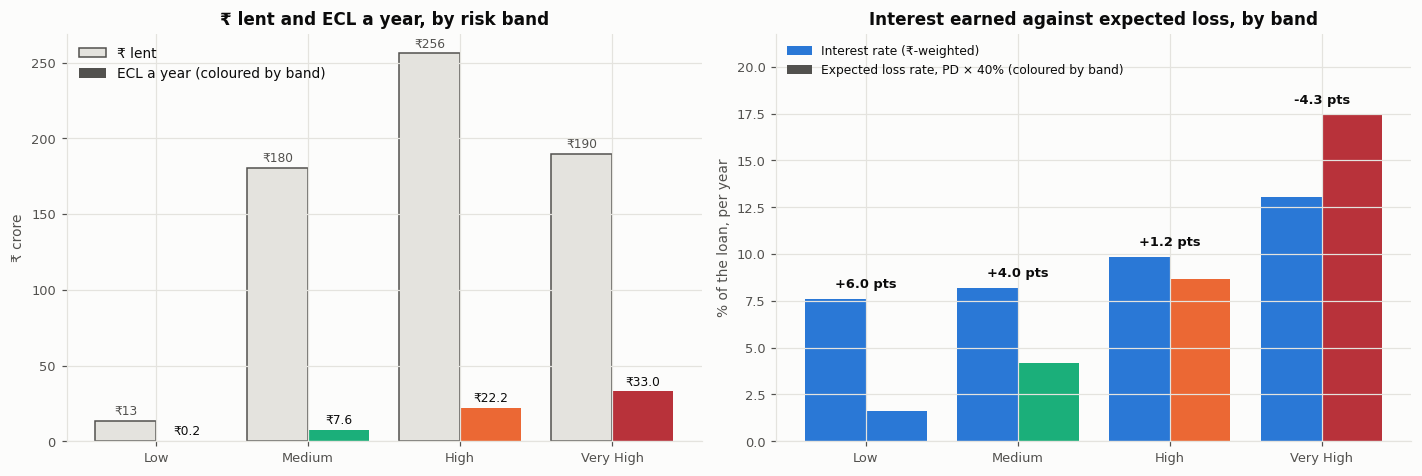

In [4]:
# Chart: ₹ lent and ECL per band, with ECL as a share of the band's lending.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
x = np.arange(len(BANDS))
lent = ecl_by_band.loc[BANDS, "₹ lent (crore)"]
ecl = ecl_by_band.loc[BANDS, "ECL (crore)"]
axes[0].bar(x - 0.2, lent, 0.4, color=GRID, edgecolor=INK_2, label="₹ lent")
axes[0].bar(x + 0.2, ecl, 0.4, color=[RISK_COLOURS[b] for b in BANDS], label="ECL a year")
for i, (l, e) in enumerate(zip(lent, ecl)):
    axes[0].text(i - 0.2, l + 4, f"₹{l:.0f}", ha="center", fontsize=8, color=INK_2)
    axes[0].text(i + 0.2, e + 4, f"₹{e:.1f}", ha="center", fontsize=8)
from matplotlib.patches import Patch                      # legend boxes that don't depend on one bar's colour
axes[0].set_xticks(x, BANDS); axes[0].set_ylabel("₹ crore")
axes[0].legend(handles=[Patch(facecolor=GRID, edgecolor=INK_2, label="₹ lent"),
                        Patch(facecolor=INK_2, label="ECL a year (coloured by band)")], frameon=False)
axes[0].set_title("₹ lent and ECL a year, by risk band")

inter = ecl_by_band.loc[BANDS, "Interest a year (crore)"] / lent
elr = ecl_by_band.loc[BANDS, "Expected loss rate"]
axes[1].bar(x - 0.2, inter * 100, 0.4, color=BLUE, label="Interest rate (₹-weighted)")
axes[1].bar(x + 0.2, elr * 100, 0.4, color=[RISK_COLOURS[b] for b in BANDS], label="Expected loss rate (PD × 40%)")
for i, (a, b) in enumerate(zip(inter, elr)):
    axes[1].text(i, max(a, b) * 100 + 0.6, f"{(a - b) * 100:+.1f} pts", ha="center", fontsize=8.5, fontweight="bold")
axes[1].set_xticks(x, BANDS); axes[1].set_ylabel("% of the loan, per year")
axes[1].legend(handles=[Patch(facecolor=BLUE, label="Interest rate (₹-weighted)"),
                        Patch(facecolor=INK_2, label="Expected loss rate, PD × 40% (coloured by band)")],
               frameon=False, fontsize=8, loc="upper left")
axes[1].set_ylim(0, max(inter.max(), elr.max()) * 100 * 1.25)
axes[1].set_title("Interest earned against expected loss, by band")
fig.tight_layout(); save_chart(fig, "01_ecl_by_band"); plt.show()

## 3. The decision rule, step by step (decisions M2-05, M2-06, M2-20)

Every loan goes through the steps in order. A loan can collect more than one Review reason; all are recorded. The step counts below cover every loan not rejected in step 1, so a large loan that is also underpriced is counted under both steps.

| Step | Rule | Brief factor | Where the threshold comes from |
| --- | --- | --- | --- |
| 1 | PD > 30% → **Reject** | PD, risk appetite | The brief's Very High band; Task 2 showed it loses money on average (margin −4.3% a year) |
| 2 | Interest rate ≤ PD × 40% → **Review**, with a required rate | ECL | The interest does not cover the expected loss (M2-05) |
| 3a | Loan in the largest 5% of the book (₹33.3 lakh or more) → **Review** | Loan size | One default loses up to about ₹29 lakh; a person should check these (concentration) |
| 3b | Interest rate ≤ PD × collateral-aware LGD → **Review** | Collateral | Interest does not cover the loss once weak collateral is counted |
| 3c | No separate override | Borrower characteristics | They act through the PD, which tracks actual default across every characteristic (step 4) |
| 4 | Approved book's expected loss rate > 6% → highest-PD Approves move to **Review** | Risk appetite | 9.1% typical interest − 3% top cost = 6.1% → 6% (M2-06) |
| — | Otherwise → **Approve** | | |

```text
Collateral-aware LGD       = max(0, 1 − 50% × Collateral_Value ÷ Loan_Amount)
                             (the bank recovers half the collateral's value in a forced sale)
Required rate              = cost + PD × max(40%, collateral-aware LGD)
                             (the lowest rate that would pass steps 2 and 3b)
```

**Flags only send loans to Review.** They never approve or reject on their own, because the 50% recovery and the 5% size cut-off are judgements the data cannot test directly.

In [5]:
def collateral_lgd(t: pd.DataFrame, recovery: float = RECOVERY) -> pd.Series:
    """Loss given default once collateral is counted: what is left after selling the collateral at `recovery`
    of its value. Never below 0 (a well-covered loan loses nothing) and never above 1."""
    return (1 - recovery * t.Collateral_Value / t.Loan_Amount).clip(0, 1)


SIZE_CUTOFF = df.Loan_Amount.quantile(1 - SIZE_SHARE)        # ₹ amount that marks the largest 5% of loans


def decide(t: pd.DataFrame, pd_col: str = "Predicted_PD", cost: float = COST, lgd: float = LGD,
           recovery: float = RECOVERY, cap: float | None = APPETITE_CAP, flags: bool = True) -> pd.DataFrame:
    """Apply the agreed rule (M2-20) to every loan and return Decision, Reason and Required_Rate.

    pd_col   : which PD drives the decision (Predicted_PD as agreed; PD_champion for the comparison)
    cost     : cost of lending as a share of the loan per year (0 in the base; 1/2/3% as sensitivity)
    lgd      : the LGD used in step 2: one number for every loan (40% base), or one value per loan
    recovery : share of collateral value recovered, for the collateral-aware LGD in step 3b
    cap      : risk-appetite cap on the approved book's expected loss rate (None = no cap)
    flags    : False switches off steps 3a and 3b (used to show what the flags add)
    """
    p = t[pd_col]
    el_flat = p * lgd                                        # expected loss rate at the flat LGD
    el_coll = p * collateral_lgd(t, recovery)                # expected loss rate once collateral is counted
    reasons = pd.Series([[] for _ in range(len(t))], index=t.index)

    # Step 1: PD above 30% -> Reject.
    reject = p > PD_REJECT
    # Step 2: interest does not cover the expected loss (plus cost) -> Review.
    under = ~reject & (t.Rate <= cost + el_flat)
    # Step 3a: the largest loans -> Review.  Step 3b: weak collateral -> Review.
    large = ~reject & (t.Loan_Amount >= SIZE_CUTOFF) & flags
    weak = ~reject & (t.Rate <= cost + el_coll) & flags
    for mask, text in [(reject, "PD over 30%"), (under, "Interest below expected loss"),
                       (large, "Large loan (largest 5%)"), (weak, "Weak collateral")]:
        for i in t.index[mask]:
            reasons[i].append(text)

    decision = pd.Series(np.where(reject, "Reject", np.where(under | large | weak, "Review", "Approve")), index=t.index)

    # Step 4: risk-appetite cap. If the approved book's expected loss rate is above the cap,
    # move the highest-PD Approves to Review, one at a time, until it is within the cap.
    if cap is not None:
        appr = t[decision == "Approve"].assign(_el=el_flat * t.Loan_Amount).sort_values(pd_col)   # safest first
        rate = appr._el.cumsum() / appr.Loan_Amount.cumsum()          # book's loss rate if we keep the first k loans
        keep = int((rate <= cap).to_numpy().nonzero()[0].max() + 1) if (rate <= cap).any() else 0
        for i in appr.index[keep:]:
            decision[i] = "Review"
            reasons[i].append("Over risk-appetite cap")

    required = cost + p * np.maximum(lgd, collateral_lgd(t, recovery))
    return pd.DataFrame({"Decision": decision,
                         "Reason": reasons.map(lambda r: "; ".join(r) if r else "Passes every test"),
                         "Required_Rate": np.where(reject, np.nan, required),
                         "Flag_Underpriced": under, "Flag_Large": large, "Flag_Weak_Collateral": weak})


res = decide(df)
df = df.drop(columns=[c for c in res.columns if c in df.columns]).join(res)
df["Decision"] = pd.Categorical(df.Decision, DECISIONS, ordered=True)
df["Rate_Rise_Needed"] = (df.Required_Rate - df.Rate).clip(lower=0)      # extra interest a Review loan needs

print(f"Size cut-off (largest {SIZE_SHARE:.0%}): ₹{SIZE_CUTOFF / LAKH:.1f} lakh")
print(df.Decision.value_counts().reindex(DECISIONS).to_string())

# How many loans each step catches (a loan can be caught by more than one step).
step_counts = pd.DataFrame({
    "Loans caught": [int((df.Predicted_PD > PD_REJECT).sum()), int(df.Flag_Underpriced.sum()),
                     int(df.Flag_Large.sum()), int(df.Flag_Weak_Collateral.sum()),
                     int(df.Reason.str.contains("cap").sum())],
    "Of which caught only by this step": [
        int((df.Predicted_PD > PD_REJECT).sum()),
        int((df.Flag_Underpriced & ~df.Flag_Large & ~df.Flag_Weak_Collateral).sum()),
        int((df.Flag_Large & ~df.Flag_Underpriced & ~df.Flag_Weak_Collateral).sum()),
        int((df.Flag_Weak_Collateral & ~df.Flag_Underpriced & ~df.Flag_Large).sum()),
        int(df.Reason.str.contains("cap").sum())]},
    index=["1  PD over 30% → Reject", "2  Interest below expected loss → Review", "3a Large loan → Review",
           "3b Weak collateral → Review", "4  Over risk-appetite cap → Review"])
save_table(step_counts.reset_index(names="Step"), "rule_steps")
step_counts

Size cut-off (largest 5%): ₹33.3 lakh
Decision
Approve    2934
Review     1045
Reject     1021


,Loans caught,Of which caught only by this step
1 PD over 30% → Reject,1021,1021
2 Interest below expected loss → Review,437,226
3a Large loan → Review,125,76
3b Weak collateral → Review,736,497
4 Over risk-appetite cap → Review,0,0


In [6]:
# The most common reasons, as recorded per loan.
reason_tbl = df.groupby(["Decision", "Reason"], observed=True).agg(
    Loans=("Loan_ID", "size"), Lent_crore=("Loan_Amount", lambda s: s.sum() / CRORE),
    Actual_default=("Default_Flag", "mean")).reset_index().sort_values(["Decision", "Loans"], ascending=[True, False])
save_table(reason_tbl.round(4), "decision_reasons")
reason_tbl.style.format({"Lent_crore": "₹{:.1f}", "Actual_default": "{:.1%}"}).hide(axis="index")

Decision,Reason,Loans,Lent_crore,Actual_default
Approve,Passes every test,2934,₹285.9,11.3%
Review,Weak collateral,497,₹58.8,19.3%
Review,Interest below expected loss,226,₹27.6,27.9%
Review,Interest below expected loss; Weak collateral,197,₹25.7,19.8%
Review,Large loan (largest 5%),76,₹32.2,23.7%
Review,Large loan (largest 5%); Weak collateral,35,₹14.2,25.7%
Review,Interest below expected loss; Large loan (largest 5%),7,₹2.6,14.3%
Review,Interest below expected loss; Large loan (largest 5%); Weak collateral,7,₹2.9,28.6%
Reject,PD over 30%,1021,₹189.8,42.7%


## 4. The evidence behind each part of the rule

Each part of the rule was tested on the data before it was agreed. This step shows that evidence. All tables use the loans that pass steps 1 and 2 (the ones the flags act on), unless stated.

**4a. Borrower characteristics (why there is no separate override).** If the PD already reflects a characteristic correctly, the predicted PD and the actual default rate move together across its range. An extra rule would then count the same risk twice.

In [7]:
pass12 = df[(df.Predicted_PD <= PD_REJECT) & ~df.Flag_Underpriced]     # loans that pass steps 1 and 2
print(f"Loans passing steps 1 and 2: {len(pass12):,}")


def pd_vs_actual(t: pd.DataFrame, col: str, fifths: bool = True) -> pd.DataFrame:
    """Actual default vs average predicted PD across a characteristic's range (fifths, or its own values)."""
    g = pd.qcut(t[col], 5, duplicates="drop") if fifths else t[col]
    out = t.groupby(g, observed=True).agg(Loans=("Loan_ID", "size"), Actual=("Default_Flag", "mean"),
                                          Predicted=("Predicted_PD", "mean"))
    out.index = [f"{col}: {i}" for i in out.index.astype(str)]
    return out


char_tbl = pd.concat([pd_vs_actual(pass12, "Debt_to_Income"), pd_vs_actual(pass12, "Credit_Score"),
                      pd_vs_actual(pass12, "Sector_Risk"), pd_vs_actual(pass12, "Employment_Length"),
                      pd_vs_actual(pass12, "Past_Default", fifths=False),
                      pd_vs_actual(pass12, "Customer_Type", fifths=False)])
char_tbl["Gap (points)"] = (char_tbl.Actual - char_tbl.Predicted) * 100
# Is any gap bigger than chance? Exact binomial test of actual defaults against the predicted average.
char_tbl["p (gap is chance?)"] = [stats.binomtest(int(round(a * n)), int(n), pr).pvalue
                                  for a, n, pr in zip(char_tbl.Actual, char_tbl.Loans, char_tbl.Predicted)]
save_table(char_tbl.round(4).reset_index(names="Group"), "evidence_characteristics")
print(f"Groups where the gap is bigger than chance (p < 0.05): {(char_tbl['p (gap is chance?)'] < 0.05).sum()} of {len(char_tbl)}")
char_tbl.style.format({"Actual": "{:.1%}", "Predicted": "{:.1%}", "Gap (points)": "{:+.1f}", "p (gap is chance?)": "{:.2f}"})

Loans passing steps 1 and 2: 3,542
Groups where the gap is bigger than chance (p < 0.05): 0 of 24


,Loans,Actual,Predicted,Gap (points),p (gap is chance?)
"Debt_to_Income: (0.028999999999999998, 0.2]",718,9.1%,10.1%,-1.1,0.35
"Debt_to_Income: (0.2, 0.286]",704,10.2%,11.9%,-1.7,0.18
"Debt_to_Income: (0.286, 0.369]",708,13.4%,13.0%,+0.4,0.74
"Debt_to_Income: (0.369, 0.484]",705,13.2%,14.9%,-1.7,0.20
"Debt_to_Income: (0.484, 0.85]",707,18.5%,17.8%,+0.8,0.59
"Credit_Score: (509.999, 653.0]",714,16.8%,17.4%,-0.6,0.73
"Credit_Score: (653.0, 691.0]",710,14.5%,15.0%,-0.5,0.75
"Credit_Score: (691.0, 724.0]",721,13.3%,13.8%,-0.4,0.79
"Credit_Score: (724.0, 763.0]",692,10.8%,12.0%,-1.2,0.38
"Credit_Score: (763.0, 850.0]",705,8.8%,9.5%,-0.7,0.56


**4b. Loan size (step 3a).** Large loans concentrate ₹ at risk. The table shows three possible cut-offs; 5% was agreed: the largest 10% doubles the Review queue, the largest 2% catches too few loans to matter. The p-value asks whether the model under-predicts large loans by more than chance.

In [8]:
size_rows = []
for share in [0.10, 0.05, 0.02]:
    cut = df.Loan_Amount.quantile(1 - share)
    big, rest = pass12[pass12.Loan_Amount >= cut], pass12[pass12.Loan_Amount < cut]
    size_rows.append({"Largest": f"{share:.0%}", "Cut-off (₹ lakh)": cut / LAKH, "Loans": len(big),
                      "₹ (crore)": big.Loan_Amount.sum() / CRORE,
                      "Share of ₹": big.Loan_Amount.sum() / pass12.Loan_Amount.sum(),
                      "Actual default": big.Default_Flag.mean(), "Predicted PD": big.Predicted_PD.mean(),
                      "Default, rest": rest.Default_Flag.mean(),
                      "Largest loss if one defaults (₹ lakh)": big.Loan_Amount.max() * LGD / LAKH,
                      "p (model under-predicts?)": stats.binomtest(int(big.Default_Flag.sum()), len(big),
                                                                   big.Predicted_PD.mean()).pvalue})
size_tbl = pd.DataFrame(size_rows)
save_table(size_tbl.round(4), "evidence_loan_size")
size_tbl.style.format({"Cut-off (₹ lakh)": "₹{:.1f}", "₹ (crore)": "₹{:.1f}", "Share of ₹": "{:.0%}",
                       "Actual default": "{:.1%}", "Predicted PD": "{:.1%}", "Default, rest": "{:.1%}",
                       "Largest loss if one defaults (₹ lakh)": "₹{:.1f}", "p (model under-predicts?)": "{:.2f}"}).hide(axis="index")

Largest,Cut-off (₹ lakh),Loans,₹ (crore),Share of ₹,Actual default,Predicted PD,"Default, rest",Largest loss if one defaults (₹ lakh),p (model under-predicts?)
10%,₹25.7,239,₹83.5,21%,22.2%,19.4%,12.2%,₹28.9,0.29
5%,₹33.3,111,₹46.4,12%,24.3%,20.2%,12.5%,₹28.9,0.29
2%,₹43.0,39,₹20.0,5%,33.3%,20.1%,12.6%,₹28.9,0.05


**4c. Collateral (step 3b).** Two facts justify how collateral enters the rule:
1. **Collateral does not predict whether a loan defaults** (Task 1): the default rate is the same whether the loan is covered or not. So it does not belong in the PD.
2. **It does change how much is lost.** A loan twice its collateral loses far more on default than one half its collateral.

**Why 50% recovery:** at 50%, the book's average collateral-aware LGD comes out close to the brief's 40%. So the total loss assumption is unchanged; it is only spread by how well each loan is covered. The data has no recovery amounts, so 50% cannot be verified, which is why weak collateral sends a loan to Review rather than Reject.

In [9]:
cover = pass12.assign(Covered=np.where(pass12.Loan_to_Value > 1, "Loan above collateral", "Loan within collateral"))
cover_tbl = cover.groupby("Covered").agg(Loans=("Loan_ID", "size"), Actual_default=("Default_Flag", "mean"),
                                         Average_PD=("Predicted_PD", "mean"))
p_cover = proportions_ztest(cover.groupby("Covered").Default_Flag.sum().to_numpy(),
                            cover.groupby("Covered").Default_Flag.size().to_numpy())[1]
print(f"1) Does collateral predict default?  p = {p_cover:.2f} (two-sided test of the two default rates)")
print(cover_tbl.to_string(float_format=lambda v: f"{v:.3f}"))

lgd_c = collateral_lgd(df)
print(f"\n2) Average collateral-aware LGD at {RECOVERY:.0%} recovery: {lgd_c.mean():.1%} by loan count, "
      f"{(lgd_c * df.Loan_Amount).sum() / df.Loan_Amount.sum():.1%} weighted by ₹ (brief: 40%)")

weak = pass12[pass12.Flag_Weak_Collateral]
ok = pass12[~pass12.Flag_Weak_Collateral]
coll_tbl = pd.DataFrame({"Flagged: weak collateral": book_summary(weak) | {"Median loan ÷ collateral": weak.Loan_to_Value.median()},
                         "Not flagged": book_summary(ok) | {"Median loan ÷ collateral": ok.Loan_to_Value.median()}}).T
save_table(coll_tbl.round(4).reset_index(names="Group"), "evidence_collateral")
coll_tbl[["Loans", "₹ lent (crore)", "Actual default rate", "Average PD", "Median loan ÷ collateral"]].style.format(
    {"Loans": "{:,.0f}", "₹ lent (crore)": "₹{:.1f}", "Actual default rate": "{:.1%}", "Average PD": "{:.1%}",
     "Median loan ÷ collateral": "{:.2f}"})

1) Does collateral predict default?  p = 0.77 (two-sided test of the two default rates)
                        Loans  Actual_default  Average_PD
Covered                                                  
Loan above collateral    1210           0.126       0.131
Loan within collateral   2332           0.130       0.138

2) Average collateral-aware LGD at 50% recovery: 37.4% by loan count, 37.5% weighted by ₹ (brief: 40%)


,Loans,₹ lent (crore),Actual default rate,Average PD,Median loan ÷ collateral
Flagged: weak collateral,532,₹72.9,19.7%,19.4%,1.38
Not flagged,"3,010",₹318.1,11.7%,12.5%,0.73


## 5. The result in ₹: Approve / Review / Reject against today's book

**How to read it:**
- "Today's book" is every loan the bank actually made.
- Expected numbers use the PD; actual numbers use what happened, at the same 40%.
- "Interest − actual loss" is what each group really earned above its credit losses in the year, before the cost of funds and running costs (step 7 adds cost).

**Is the drop in default rate real?** A one-sided two-proportion z test compares the Approve default rate with today's book. The 95% Wilson range is shown for each group's default rate. A bootstrap (1,000 resamples) gives a 95% range for what Approve earns.

In [10]:
outcome = pd.DataFrame({d: book_summary(df[df.Decision == d]) for d in DECISIONS}).T
outcome.loc["Today's book"] = book_summary(df)
outcome["Share of loans"] = outcome.Loans / len(df)
outcome["Share of ₹"] = outcome["₹ lent (crore)"] / outcome.loc["Today's book", "₹ lent (crore)"]
lo, hi = proportion_confint((outcome["Actual default rate"] * outcome.Loans).round(), outcome.Loans, method="wilson")
outcome["Default 95% range"] = [f"{a:.1%} to {b:.1%}" for a, b in zip(lo, hi)]
save_table(outcome.round(4).reset_index(names="Group"), "decision_outcome")

# Significance: Approve's default rate vs today's book (one-sided: is it lower?).
appr = df[df.Decision == "Approve"]
z, p_drop = proportions_ztest([appr.Default_Flag.sum(), df.Default_Flag.sum()], [len(appr), len(df)], alternative="smaller")

# Bootstrap: what does the Approve group earn above actual loss, and how sure are we?
rng = np.random.default_rng(SEED)
vals = appr[["Interest_Year", "Actual_Loss"]].to_numpy()
boot = np.array([(lambda s: (s[:, 0].sum() - s[:, 1].sum()) / CRORE)(vals[rng.integers(0, len(vals), len(vals))])
                 for _ in range(1000)])
EARN_RANGE = np.percentile(boot, [2.5, 97.5])
book_earn = outcome.loc["Today's book", "Interest − actual loss (crore)"]

print(f"Approve default rate {appr.Default_Flag.mean():.1%} vs today's {df.Default_Flag.mean():.1%}: z = {z:.1f}, p = {p_drop:.1e}")
print(f"Approve earns ₹{outcome.loc['Approve', 'Interest − actual loss (crore)']:.2f} crore a year above actual loss "
      f"(95% range ₹{EARN_RANGE[0]:.2f} to ₹{EARN_RANGE[1]:.2f} crore); today's whole book ₹{book_earn:.2f} crore")
show_cols = ["Loans", "Share of loans", "₹ lent (crore)", "Share of ₹", "Actual default rate", "Default 95% range",
             "Expected loss rate", "Actual loss rate", "Interest − ECL (crore)", "Interest − actual loss (crore)"]
outcome[show_cols].style.format({"Loans": "{:,.0f}", "Share of loans": "{:.0%}", "₹ lent (crore)": "₹{:.1f}",
                                 "Share of ₹": "{:.0%}", "Actual default rate": "{:.1%}", "Expected loss rate": "{:.2%}",
                                 "Actual loss rate": "{:.2%}", "Interest − ECL (crore)": "₹{:+.2f}",
                                 "Interest − actual loss (crore)": "₹{:+.2f}"})

Approve default rate 11.3% vs today's 19.9%: z = -9.9, p = 2.3e-23
Approve earns ₹10.45 crore a year above actual loss (95% range ₹8.62 to ₹12.11 crore); today's whole book ₹3.07 crore


,Loans,Share of loans,₹ lent (crore),Share of ₹,Actual default rate,Default 95% range,Expected loss rate,Actual loss rate,Interest − ECL (crore),Interest − actual loss (crore)
Approve,"2,934",59%,₹285.9,45%,11.3%,10.3% to 12.5%,5.45%,5.10%,₹+9.44,₹+10.45
Review,"1,045",21%,₹163.9,26%,21.8%,19.4% to 24.4%,8.79%,9.40%,₹+1.58,₹+0.59
Reject,"1,021",20%,₹189.8,30%,42.7%,39.7% to 45.8%,17.41%,17.25%,₹-8.25,₹-7.96
Today's book,"5,000",100%,₹639.7,100%,19.9%,18.9% to 21.1%,9.86%,9.81%,₹+2.76,₹+3.07


**Consistency on the 1,000 test loans.** The rule was agreed using all 5,000 loans, whose PDs are all honest (Task 2). As a check, the same table on the 1,000 test loans only (never used to choose anything in Task 1) should show the same pattern: default rate rising from Approve to Review to Reject, and Approve well below today's book.

In [11]:
test = df[df.Is_Test]
outcome_test = pd.DataFrame({d: book_summary(test[test.Decision == d]) for d in DECISIONS}).T
outcome_test.loc["Today's book"] = book_summary(test)
save_table(outcome_test.round(4).reset_index(names="Group"), "decision_outcome_test_loans")
rates = outcome_test.loc[DECISIONS, "Actual default rate"]
TEST_CONSISTENT = bool(rates.is_monotonic_increasing and rates["Approve"] < outcome_test.loc["Today's book", "Actual default rate"])
print("Consistent on the test loans (rising default, Approve below today's):", TEST_CONSISTENT)
outcome_test[["Loans", "₹ lent (crore)", "Actual default rate", "Expected loss rate", "Actual loss rate",
              "Interest − actual loss (crore)"]].style.format({"Loans": "{:,.0f}", "₹ lent (crore)": "₹{:.1f}",
              "Actual default rate": "{:.1%}", "Expected loss rate": "{:.2%}", "Actual loss rate": "{:.2%}",
              "Interest − actual loss (crore)": "₹{:+.2f}"})

Consistent on the test loans (rising default, Approve below today's): True


,Loans,₹ lent (crore),Actual default rate,Expected loss rate,Actual loss rate,Interest − actual loss (crore)
Approve,541,₹51.4,11.3%,5.45%,5.38%,₹+1.70
Review,242,₹37.5,21.1%,9.09%,9.40%,₹+0.16
Reject,217,₹39.0,40.1%,17.07%,16.54%,₹-1.30
Today's book,"1,000",₹127.9,19.9%,10.06%,9.96%,₹+0.55


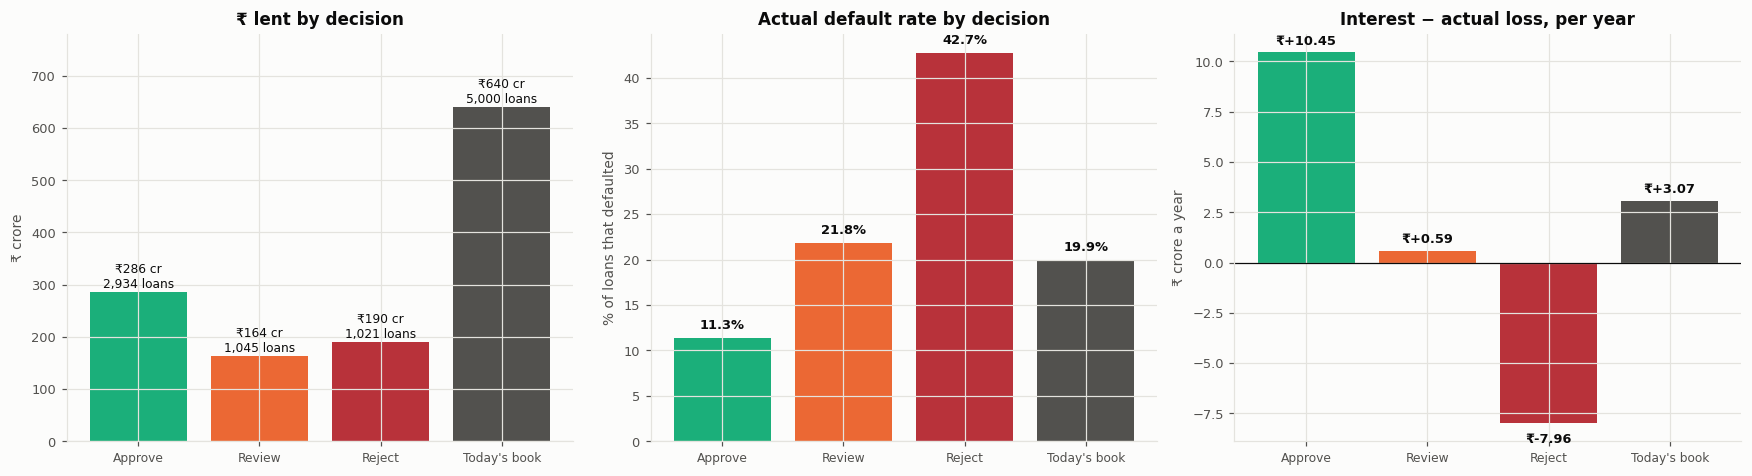

In [12]:
# Chart: where the ₹ go under the rule, and what each group really did.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
groups = DECISIONS + ["Today's book"]
cols = [DECISION_COLOURS[g] for g in groups]

v = outcome.loc[groups, "₹ lent (crore)"]
axes[0].bar(groups, v, color=cols)
for i, a in enumerate(v):
    axes[0].text(i, a + 8, f"₹{a:.0f} cr\n{outcome.loc[groups[i], 'Loans']:,.0f} loans", ha="center", fontsize=8)
axes[0].set_ylabel("₹ crore"); axes[0].set_title("₹ lent by decision"); axes[0].set_ylim(0, v.max() * 1.22)

r = outcome.loc[groups, "Actual default rate"] * 100
axes[1].bar(groups, r, color=cols)
for i, a in enumerate(r):
    axes[1].text(i, a + 1, f"{a:.1f}%", ha="center", fontsize=8.5, fontweight="bold")
axes[1].set_ylabel("% of loans that defaulted"); axes[1].set_title("Actual default rate by decision")

e = outcome.loc[groups, "Interest − actual loss (crore)"]
axes[2].bar(groups, e, color=cols)
axes[2].axhline(0, color=INK, lw=0.8)
for i, a in enumerate(e):
    axes[2].text(i, a + (0.4 if a >= 0 else -1.0), f"₹{a:+.2f}", ha="center", fontsize=8.5, fontweight="bold")
axes[2].set_ylabel("₹ crore a year"); axes[2].set_title("Interest − actual loss, per year")
for ax in axes:
    ax.tick_params(axis="x", labelsize=8)
fig.tight_layout(); save_chart(fig, "02_decision_outcome"); plt.show()

## 6. Risk appetite: the trade-off table (decision M2-06)

**Risk appetite** = how much loss the Board is willing to accept to earn its income. Here it is a cap on the approved book's **expected loss rate** = total ECL ÷ total ₹ approved.

**How 6% was arrived at:**
```text
cap = typical interest rate − highest cost of lending assumed = 9.1% (median Interest_Rate) − 3% (top of the 1–3% range) = 6.1% → 6%
```
In plain terms: even at the highest cost we assume, the approved book's expected loss must not use up all of its interest.

**Why the table matters:** every loan a tighter cap removes still earns more than its expected loss (it passed step 2). So a stricter cap is a Board choice of safety over income. The table shows that choice in ₹. When a cap is hit, the highest-PD loans move to Review first.

In [13]:
trade_rows = [{"Setting": "Today's book (every loan made)"} | book_summary(df)]
for cap in CAPS:
    d_ = decide(df, cap=cap)
    a_ = df[d_.Decision == "Approve"]
    trade_rows.append({"Setting": "Rule, no cap" if cap is None else f"Rule, cap {cap:.0%}" + (" (agreed)" if cap == APPETITE_CAP else "")}
                      | book_summary(a_) | {"Moved to Review by the cap": int(d_.Reason.str.contains("cap").sum())})
trade = pd.DataFrame(trade_rows).set_index("Setting")
save_table(trade.round(4).reset_index(), "risk_appetite_tradeoff")
CAP_BINDS = bool(trade.loc["Rule, cap 6% (agreed)", "Moved to Review by the cap"] > 0)
print("Does the agreed 6% cap move any loan?", CAP_BINDS)
trade[["Loans", "₹ lent (crore)", "Expected loss rate", "Actual loss rate", "Actual default rate",
       "Interest − ECL (crore)", "Interest − actual loss (crore)", "Moved to Review by the cap"]].style.format(
    {"Loans": "{:,.0f}", "₹ lent (crore)": "₹{:.1f}", "Expected loss rate": "{:.2%}", "Actual loss rate": "{:.2%}",
     "Actual default rate": "{:.1%}", "Interest − ECL (crore)": "₹{:+.2f}", "Interest − actual loss (crore)": "₹{:+.2f}",
     "Moved to Review by the cap": "{:,.0f}"}, na_rep="—")

Does the agreed 6% cap move any loan? False


,Loans,₹ lent (crore),Expected loss rate,Actual loss rate,Actual default rate,Interest − ECL (crore),Interest − actual loss (crore),Moved to Review by the cap
Setting,,,,,,,,
Today's book (every loan made),"5,000",₹639.7,9.86%,9.81%,19.9%,₹+2.76,₹+3.07,—
"Rule, no cap","2,934",₹285.9,5.45%,5.10%,11.3%,₹+9.44,₹+10.45,0
"Rule, cap 6% (agreed)","2,934",₹285.9,5.45%,5.10%,11.3%,₹+9.44,₹+10.45,0
"Rule, cap 5%","2,755",₹260.1,5.00%,4.59%,10.5%,₹+9.16,₹+10.23,179
"Rule, cap 4%","2,106",₹182.3,4.00%,3.71%,8.7%,₹+7.59,₹+8.11,828
"Rule, cap 3%","1,252",₹97.3,3.00%,2.80%,6.9%,₹+4.67,₹+4.86,"1,682"


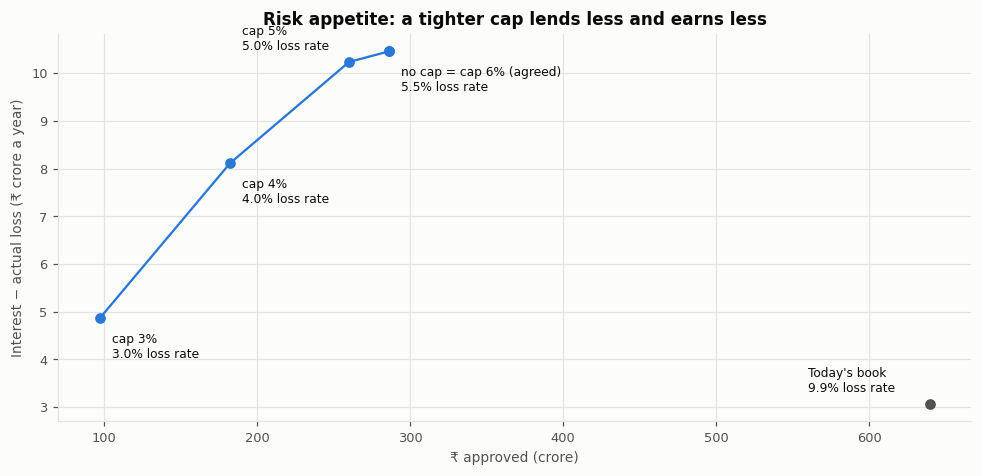

In [14]:
# Chart: what each cap level costs in ₹ approved and income.
t_ = trade.drop(index="Today's book (every loan made)")
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(t_["₹ lent (crore)"], t_["Interest − actual loss (crore)"], "o-", color=BLUE)
# Points with identical results (e.g. "no cap" and the agreed 6% when the cap does not bind) share one label.
labels_at = {}
for name, row in t_.iterrows():
    key_xy = (round(row["₹ lent (crore)"], 3), round(row["Interest − actual loss (crore)"], 3))
    labels_at.setdefault(key_xy, []).append(name.replace("Rule, ", ""))
for (x_, y_), names in labels_at.items():
    rate_ = t_.loc[[n for n in t_.index if n.replace("Rule, ", "") == names[0]][0], "Expected loss rate"]
    above_left = names == ["cap 5%"]                       # sits next to the agreed point: label it on the other side
    ax.annotate(" = ".join(names) + f"\n{rate_:.1%} loss rate", (x_, y_), textcoords="offset points",
                xytext=(-70, 8) if above_left else (8, -26), fontsize=8)
tb = trade.loc["Today's book (every loan made)"]
ax.scatter([tb["₹ lent (crore)"]], [tb["Interest − actual loss (crore)"]], color=INK_2, zorder=3)
ax.annotate(f"Today's book\n{tb['Expected loss rate']:.1%} loss rate", (tb["₹ lent (crore)"], tb["Interest − actual loss (crore)"]),
            textcoords="offset points", xytext=(-80, 8), fontsize=8)
ax.set_xlabel("₹ approved (crore)"); ax.set_ylabel("Interest − actual loss (₹ crore a year)")
ax.set_title("Risk appetite: a tighter cap lends less and earns less")
fig.tight_layout(); save_chart(fig, "03_risk_appetite_tradeoff"); plt.show()

## 7. Sensitivity to the cost of lending (decision M2-05)

The bank pays for its money (deposits, borrowing) and to run each loan. The data gives no figure, so the base test uses none, as in the assignment guide, and 1%, 2% and 3% are tested here.

```text
At cost c:  step 2 becomes  Interest rate ≤ c + PD × 40%  → Review;  required rate = c + PD × max(40%, collateral-aware LGD)
Earnings after cost = Interest − actual loss − c × ₹ lent
```

Cost only moves loans between Approve and Review: Reject depends on PD alone.

In [15]:
cost_rows = []
for c in COSTS:
    d_ = decide(df, cost=c)
    a_ = df[d_.Decision == "Approve"]
    rv = d_.Decision == "Review"
    rise = (d_.Required_Rate - df.Rate).clip(lower=0)[rv & d_.Flag_Underpriced]
    cost_rows.append({"Cost of lending": f"{c:.0%}", "Approve": int((d_.Decision == "Approve").sum()),
                      "Review": int(rv.sum()), "Reject": int((d_.Decision == "Reject").sum()),
                      "₹ approved (crore)": a_.Loan_Amount.sum() / CRORE, "Approved default rate": a_.Default_Flag.mean(),
                      "Median rate rise for underpriced Review loans (points)": rise.median() * 100,
                      "Approved: interest − actual loss − cost (crore)":
                          (a_.Interest_Year.sum() - a_.Actual_Loss.sum() - c * a_.Loan_Amount.sum()) / CRORE,
                      "Today's book: interest − actual loss − cost (crore)":
                          (df.Interest_Year.sum() - df.Actual_Loss.sum() - c * df.Loan_Amount.sum()) / CRORE})
cost_tbl = pd.DataFrame(cost_rows).set_index("Cost of lending")
save_table(cost_tbl.round(4).reset_index(), "sensitivity_cost")
BOOK_BREAKEVEN_COST = (df.Interest_Year.sum() - df.Actual_Loss.sum()) / df.Loan_Amount.sum()
print(f"Today's book breaks even at a cost of {BOOK_BREAKEVEN_COST:.2%} a year; above that it loses money.")
cost_tbl.style.format({"₹ approved (crore)": "₹{:.1f}", "Approved default rate": "{:.1%}",
                       "Median rate rise for underpriced Review loans (points)": "+{:.2f}",
                       "Approved: interest − actual loss − cost (crore)": "₹{:+.2f}",
                       "Today's book: interest − actual loss − cost (crore)": "₹{:+.2f}"})

Today's book breaks even at a cost of 0.48% a year; above that it loses money.


,Approve,Review,Reject,₹ approved (crore),Approved default rate,Median rate rise for underpriced Review loans (points),Approved: interest − actual loss − cost (crore),Today's book: interest − actual loss − cost (crore)
Cost of lending,,,,,,,,
0%,2934,1045,1021,₹285.9,11.3%,+1.64,₹+10.45,₹+3.07
1%,2521,1458,1021,₹236.1,10.6%,+2.10,₹+6.85,₹-3.32
2%,2006,1973,1021,₹179.0,9.1%,+2.38,₹+4.40,₹-9.72
3%,1432,2547,1021,₹120.5,8.8%,+2.70,₹+2.16,₹-16.11


## 8. Sensitivity to LGD (decision M2-03)

The data has no recovery amounts, so LGD cannot be measured. The base uses the brief's flat 40%. Two kinds of alternatives are tested:
- **Flat LGD at 30%, 50% and 60%**: every loan loses the same share on default.
- **Collateral-aware LGD at 50%, 60% and 70% recovery**: LGD = max(0, 1 − recovery × collateral ÷ loan), used in place of the flat LGD in step 2, with step 3b at the same recovery.

For each, the table shows total ECL against the actual loss at that same LGD (is the ECL still right?), and how many decisions change compared with the base.

In [16]:
base_dec = df.Decision.astype(str)
lgd_rows = []
for kind, val in [("Flat", 0.30), ("Flat", 0.40), ("Flat", 0.50), ("Flat", 0.60),
                  ("Collateral-aware", 0.50), ("Collateral-aware", 0.60), ("Collateral-aware", 0.70)]:
    if kind == "Flat":
        lgd_i = pd.Series(val, index=df.index)
        d_ = decide(df, lgd=val)
        name = f"Flat {val:.0%}" + (" (base)" if val == LGD else "")
    else:
        lgd_i = collateral_lgd(df, val)
        # Use the loan's collateral-aware LGD in step 2 by passing it through a temporary PD column.
        # Each loan's own collateral-aware LGD replaces the flat 40% in step 2, and step 3b uses the same recovery,
        # so the two steps apply one consistent view of collateral.
        d_ = decide(df, lgd=lgd_i, recovery=val)
        name = f"Collateral-aware, {val:.0%} recovery"
    ecl_i = df.Predicted_PD * lgd_i * df.Loan_Amount
    a_ = df[d_.Decision == "Approve"]
    lgd_rows.append({"LGD": name, "Average LGD (₹-weighted)": (lgd_i * df.Loan_Amount).sum() / df.Loan_Amount.sum(),
                     "Total ECL (crore)": ecl_i.sum() / CRORE,
                     "Actual loss at this LGD (crore)": (df.Default_Flag * lgd_i * df.Loan_Amount).sum() / CRORE,
                     "Approve": int((d_.Decision == "Approve").sum()), "Review": int((d_.Decision == "Review").sum()),
                     "Reject": int((d_.Decision == "Reject").sum()),
                     "Decisions changed vs base": int((d_.Decision.astype(str) != base_dec).sum()),
                     "Approved default rate": a_.Default_Flag.mean(),
                     "Approved: interest − actual loss at this LGD (crore)":
                         (a_.Interest_Year.sum() - (a_.Default_Flag * lgd_i[a_.index] * a_.Loan_Amount).sum()) / CRORE})
lgd_tbl = pd.DataFrame(lgd_rows).set_index("LGD")
save_table(lgd_tbl.round(4).reset_index(), "sensitivity_lgd")
UNDER_COLLATERALISED = int((df.Loan_to_Value > 1).sum())
print(f"Loans bigger than their collateral: {UNDER_COLLATERALISED:,} "
      f"(₹{df.loc[df.Loan_to_Value > 1, 'Loan_Amount'].sum() / CRORE:.1f} crore)")
lgd_tbl.style.format({"Average LGD (₹-weighted)": "{:.1%}", "Total ECL (crore)": "₹{:.1f}",
                      "Actual loss at this LGD (crore)": "₹{:.1f}", "Approved default rate": "{:.1%}",
                      "Approved: interest − actual loss at this LGD (crore)": "₹{:+.2f}"})

Loans bigger than their collateral: 1,665 (₹212.7 crore)


,Average LGD (₹-weighted),Total ECL (crore),Actual loss at this LGD (crore),Approve,Review,Reject,Decisions changed vs base,Approved default rate,Approved: interest − actual loss at this LGD (crore)
LGD,,,,,,,,,
Flat 30%,30.0%,₹47.3,₹47.0,3154,825,1021,220,12.6%,₹+14.27
Flat 40% (base),40.0%,₹63.0,₹62.7,2934,1045,1021,0,11.3%,₹+10.45
Flat 50%,50.0%,₹78.8,₹78.4,2444,1535,1021,490,9.9%,₹+6.74
Flat 60%,60.0%,₹94.6,₹94.1,1954,2025,1021,980,8.6%,₹+4.81
"Collateral-aware, 50% recovery",37.5%,₹58.3,₹57.6,3160,819,1021,226,12.5%,₹+14.91
"Collateral-aware, 60% recovery",27.3%,₹42.3,₹41.6,3407,572,1021,473,13.4%,₹+19.87
"Collateral-aware, 70% recovery",20.3%,₹31.3,₹30.6,3532,447,1021,598,13.4%,₹+24.01


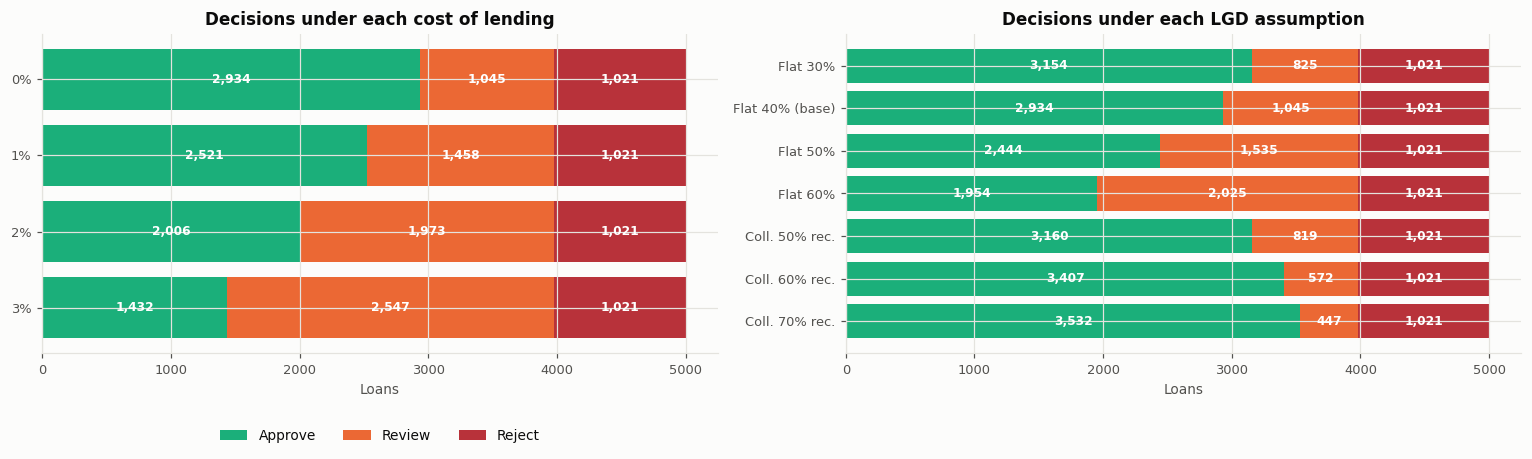

In [17]:
# Chart: how the decision split moves with cost of lending and with LGD.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for ax, tbl, title in [(axes[0], cost_tbl, "cost of lending"), (axes[1], lgd_tbl, "LGD assumption")]:
    labels = [str(i).replace("Collateral-aware, ", "Coll. ").replace(" recovery", " rec.") for i in tbl.index]
    left = np.zeros(len(tbl))
    for d in DECISIONS:
        ax.barh(labels, tbl[d], left=left, color=DECISION_COLOURS[d], label=d)
        for i, (l, v) in enumerate(zip(left, tbl[d])):
            if v > 250:
                ax.text(l + v / 2, i, f"{v:,}", ha="center", va="center", fontsize=8, color="white", fontweight="bold")
        left += tbl[d].to_numpy()
    ax.invert_yaxis(); ax.set_xlabel("Loans"); ax.set_title(f"Decisions under each {title}")
axes[0].legend(frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.32))
fig.tight_layout(); save_chart(fig, "04_sensitivity"); plt.show()

## 9. Scorecard PD against the bank's own view (decision M2-19)

The rule uses the scorecard's PD (`Predicted_PD`). Two comparisons with the **champion** (the PD implied by the interest rate the bank charged):

1. **The same rule, run on each PD.** Shows what the scorecard adds to the *decision*.
2. **Ranking alone, at equal approval levels.** Approve the safest x% under each PD and compare actual loss. Task 1 found the scorecard's ranking advantage reverses above about 73% approval; this checks where our rule sits.

In [18]:
champ = decide(df, pd_col="PD_champion")
cmp_rows = []
for name, dec in [("Scorecard PD (used)", df.Decision.astype(str)), ("Champion PD (bank's price)", champ.Decision)]:
    a_ = df[dec == "Approve"]
    cmp_rows.append({"PD used": name, "Approve": int((dec == "Approve").sum()), "Review": int((dec == "Review").sum()),
                     "Reject": int((dec == "Reject").sum()), "₹ approved (crore)": a_.Loan_Amount.sum() / CRORE,
                     "Approved default rate": a_.Default_Flag.mean(),
                     "Approved actual loss rate": a_.Actual_Loss.sum() / a_.Loan_Amount.sum(),
                     "Approved: interest − actual loss (crore)": (a_.Interest_Year.sum() - a_.Actual_Loss.sum()) / CRORE,
                     "Per ₹100 approved": 100 * (a_.Interest_Year.sum() - a_.Actual_Loss.sum()) / a_.Loan_Amount.sum()})
cmp_tbl = pd.DataFrame(cmp_rows).set_index("PD used")
save_table(cmp_tbl.round(4).reset_index(), "scorecard_vs_champion_rule")
cmp_tbl.style.format({"₹ approved (crore)": "₹{:.1f}", "Approved default rate": "{:.1%}",
                      "Approved actual loss rate": "{:.2%}", "Approved: interest − actual loss (crore)": "₹{:+.2f}",
                      "Per ₹100 approved": "₹{:.2f}"})

,Approve,Review,Reject,₹ approved (crore),Approved default rate,Approved actual loss rate,Approved: interest − actual loss (crore),Per ₹100 approved
PD used,,,,,,,,
Scorecard PD (used),2934,1045,1021,₹285.9,11.3%,5.10%,₹+10.45,₹3.66
Champion PD (bank's price),3210,958,832,₹322.4,14.0%,6.36%,₹+7.36,₹2.28


In [19]:
APPROVAL_SHARE = float((df.Decision == "Approve").mean())       # the rule's approval level
PASS12_SHARE = float(((df.Predicted_PD <= PD_REJECT) & ~df.Flag_Underpriced).mean())   # before the flags


def ranking_saving(t: pd.DataFrame, share: float) -> float:
    """Approve the safest `share` of loans under each PD; return the champion's actual loss minus the scorecard's (₹ crore).
    Positive = the scorecard loses less."""
    k = int(round(share * len(t)))
    return (t.nsmallest(k, "PD_champion").Actual_Loss.sum() - t.nsmallest(k, "Predicted_PD").Actual_Loss.sum()) / CRORE


levels = sorted({0.50, 0.55, 0.60, 0.65, 0.70, TURNING_POINT, 0.75, 0.80, round(APPROVAL_SHARE, 3), round(PASS12_SHARE, 3)})
rank_tbl = pd.DataFrame({"Approval level": [f"{s:.1%}" for s in levels],
                         "Scorecard saving, all 5,000 (₹ crore)": [ranking_saving(df, s) for s in levels],
                         "Scorecard saving, 1,000 test loans (₹ crore)": [ranking_saving(df[df.Is_Test], s) for s in levels]})
rank_tbl["Note"] = ["the rule's approval level" if abs(s - APPROVAL_SHARE) < 1e-3 else
                    "steps 1–2 only (before flags)" if abs(s - PASS12_SHARE) < 1e-3 else
                    "Task 1 turning point" if s == TURNING_POINT else "" for s in levels]
save_table(rank_tbl.round(4), "scorecard_vs_champion_ranking")
print(f"The rule approves {APPROVAL_SHARE:.1%} of loans (steps 1–2 alone: {PASS12_SHARE:.1%}); Task 1 turning point: {TURNING_POINT:.0%}")
rank_tbl.style.format({"Scorecard saving, all 5,000 (₹ crore)": "₹{:+.2f}",
                       "Scorecard saving, 1,000 test loans (₹ crore)": "₹{:+.2f}"}).hide(axis="index")

The rule approves 58.7% of loans (steps 1–2 alone: 70.8%); Task 1 turning point: 73%


Approval level,"Scorecard saving, all 5,000 (₹ crore)","Scorecard saving, 1,000 test loans (₹ crore)",Note
50.0%,₹+2.03,₹-0.02,
55.0%,₹+2.13,₹+0.34,
58.7%,₹+1.93,₹+0.40,the rule's approval level
60.0%,₹+1.59,₹+0.40,
65.0%,₹+0.61,₹+0.23,
70.0%,₹+0.22,₹-0.26,
70.8%,₹+0.23,₹-0.21,steps 1–2 only (before flags)
73.0%,₹-0.65,₹-0.04,Task 1 turning point
75.0%,₹-0.98,₹-0.64,
80.0%,₹-1.23,₹-0.17,


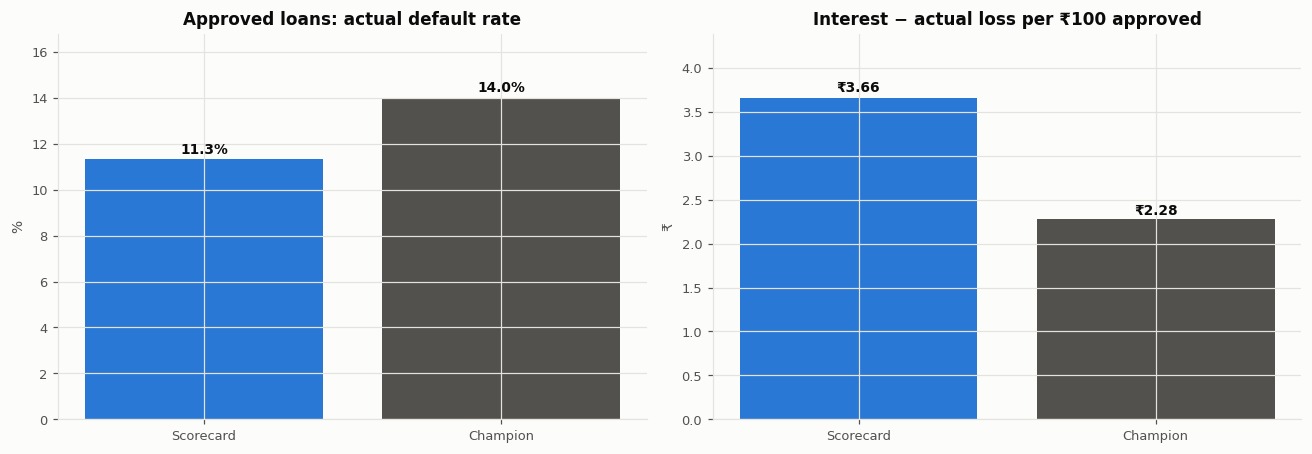

In [20]:
# Chart: the same rule on each PD, in ₹.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
names = ["Scorecard PD (used)", "Champion PD (bank's price)"]
for ax, col, fmt, title in [(axes[0], "Approved default rate", "{:.1%}", "Approved loans: actual default rate"),
                            (axes[1], "Per ₹100 approved", "₹{:.2f}", "Interest − actual loss per ₹100 approved")]:
    vals = cmp_tbl.loc[names, col] * (100 if "rate" in col else 1)
    ax.bar(["Scorecard", "Champion"], vals, color=[BLUE, INK_2])
    for i, v in enumerate(cmp_tbl.loc[names, col]):
        ax.text(i, vals.iloc[i] * 1.02, fmt.format(v), ha="center", fontsize=9, fontweight="bold")
    ax.set_title(title); ax.set_ylim(0, vals.max() * 1.2)
axes[0].set_ylabel("%"); axes[1].set_ylabel("₹")
fig.tight_layout(); save_chart(fig, "05_scorecard_vs_champion"); plt.show()

## 10. Concentration, results by segment, and example loans

**Concentration** (reported, not capped, M2-06): how the approved book splits by customer type and sector risk compared with today's book. The data gives no basis for a limit, so this is for the Board to watch.

In [21]:
df["Sector_Risk_Fifth"] = pd.qcut(df.Sector_Risk, 5, labels=["Lowest", "Low", "Middle", "High", "Highest"])
conc = []
for col in ["Customer_Type", "Sector_Risk_Fifth"]:
    for g, t in df.groupby(col, observed=True):
        a_ = t[t.Decision == "Approve"]
        conc.append({"Group": f"{col.replace('_Fifth', '')}: {g}",
                     "Share of today's ₹": t.Loan_Amount.sum() / df.Loan_Amount.sum(),
                     "Share of approved ₹": a_.Loan_Amount.sum() / df.loc[df.Decision == "Approve", "Loan_Amount"].sum(),
                     "Approval rate": len(a_) / len(t), "Approved default rate": a_.Default_Flag.mean()})
conc_tbl = pd.DataFrame(conc)
save_table(conc_tbl.round(4), "concentration")
conc_tbl.style.format({c: "{:.1%}" for c in conc_tbl.columns if c != "Group"}).hide(axis="index")

Group,Share of today's ₹,Share of approved ₹,Approval rate,Approved default rate
Customer_Type: Corporate,27.1%,26.4%,58.6%,11.4%
Customer_Type: Retail,72.9%,73.6%,58.7%,11.3%
Sector_Risk: Lowest,19.1%,20.0%,60.3%,10.1%
Sector_Risk: Low,20.4%,20.6%,58.8%,10.7%
Sector_Risk: Middle,19.9%,18.8%,56.5%,9.9%
Sector_Risk: High,19.9%,20.5%,60.0%,13.2%
Sector_Risk: Highest,20.7%,20.1%,57.8%,12.8%


**Results by segment** (decision M2-22). How each segment fares today and under the rule: Retail and Corporate, and each fifth of sector risk. Task 1 step 8b showed the segments default alike and one model serves both; this shows what that means in ₹ for each part of the book.

```text
Today: every loan the bank made in the segment.   Rule: the loans the rule approves in that segment.
Interest − actual loss = interest a year − Default_Flag × 40% × loan   (what the loans really earned above credit losses)
Expected return = interest rate − ECL rate                            (the measure Module 9 uses)
```

In [22]:
segment_rows = []
segments = [("Customer type", g, t) for g, t in df.groupby("Customer_Type", observed=True)] +            [("Sector risk", f"{g} fifth", t) for g, t in df.groupby("Sector_Risk_Fifth", observed=True)]
for kind, g, t in segments:
    a_ = t[t.Decision == "Approve"]
    segment_rows.append({
        "Kind": kind, "Segment": g, "Loans": len(t), "₹ lent today (crore)": t.Loan_Amount.sum() / CRORE,
        "Approve": (t.Decision == "Approve").mean(), "Review": (t.Decision == "Review").mean(),
        "Reject": (t.Decision == "Reject").mean(),
        "Default today": t.Default_Flag.mean(), "Default, approved": a_.Default_Flag.mean(),
        "Interest − actual loss today (crore)": (t.Interest_Year.sum() - t.Actual_Loss.sum()) / CRORE,
        "Interest − actual loss, approved (crore)": (a_.Interest_Year.sum() - a_.Actual_Loss.sum()) / CRORE,
        "Earned per ₹100 today": 100 * (t.Interest_Year.sum() - t.Actual_Loss.sum()) / t.Loan_Amount.sum(),
        "Earned per ₹100, approved": 100 * (a_.Interest_Year.sum() - a_.Actual_Loss.sum()) / a_.Loan_Amount.sum(),
        "Expected return today": (t.Interest_Year.sum() - t.ECL.sum()) / t.Loan_Amount.sum(),
        "Expected return, approved": (a_.Interest_Year.sum() - a_.ECL.sum()) / a_.Loan_Amount.sum()})
seg_res = pd.DataFrame(segment_rows)
save_table(seg_res.round(4), "results_by_segment")

# Is the approved default rate the same in Retail and Corporate?  (two-proportion z test)
ar = df[df.Decision == "Approve"]
p_seg_appr = proportions_ztest(ar.groupby("Customer_Type", observed=True).Default_Flag.sum().to_numpy(),
                               ar.groupby("Customer_Type", observed=True).Default_Flag.size().to_numpy())[1]
print(f"Approved loans, Retail vs Corporate default rate: p = {p_seg_appr:.2f}")

# Is today's earnings gap between Retail and Corporate bigger than chance?  Bootstrap (1,000 resamples)
# of ₹ earned above credit losses per ₹100 lent, in each segment and for the difference.
rng_s = np.random.default_rng(SEED)
earn_parts = {g: t[["Interest_Year", "Actual_Loss", "Loan_Amount"]].to_numpy()
              for g, t in df.groupby("Customer_Type", observed=True)}


def per100(v):
    """₹ earned above credit losses per ₹100 lent."""
    return 100 * (v[:, 0].sum() - v[:, 1].sum()) / v[:, 2].sum()


boot_seg = {g: [] for g in earn_parts}
for _ in range(1000):
    for g, v in earn_parts.items():
        boot_seg[g].append(per100(v[rng_s.integers(0, len(v), len(v))]))
gap = np.array(boot_seg["Retail"]) - np.array(boot_seg["Corporate"])
SEG_GAP = {"Retail": np.percentile(boot_seg["Retail"], [2.5, 97.5]),
           "Corporate": np.percentile(boot_seg["Corporate"], [2.5, 97.5]),
           "Retail − Corporate": np.percentile(gap, [2.5, 97.5])}
for k, (lo_, hi_) in SEG_GAP.items():
    print(f"Today, ₹ earned per ₹100 lent, 95% range — {k}: ₹{lo_:+.2f} to ₹{hi_:+.2f}")
CORP_GAP_REAL = bool(SEG_GAP["Retail − Corporate"][0] > 0)
print("Is Corporate's lower earning today bigger than chance?", CORP_GAP_REAL)
seg_res.style.format({c: "{:.1%}" for c in ["Approve", "Review", "Reject", "Default today", "Default, approved",
                                            "Expected return today", "Expected return, approved"]} |
                     {c: "₹{:+.2f}" for c in seg_res.columns if "crore" in c and "Interest" in c} |
                     {"₹ lent today (crore)": "₹{:.1f}", "Earned per ₹100 today": "₹{:.2f}",
                      "Earned per ₹100, approved": "₹{:.2f}"}).hide(axis="index")

Approved loans, Retail vs Corporate default rate: p = 0.98
Today, ₹ earned per ₹100 lent, 95% range — Retail: ₹-0.09 to ₹+1.33
Today, ₹ earned per ₹100 lent, 95% range — Corporate: ₹-1.02 to ₹+1.40
Today, ₹ earned per ₹100 lent, 95% range — Retail − Corporate: ₹-0.90 to ₹+1.91
Is Corporate's lower earning today bigger than chance? False


Kind,Segment,Loans,₹ lent today (crore),Approve,Review,Reject,Default today,"Default, approved",Interest − actual loss today (crore),"Interest − actual loss, approved (crore)",Earned per ₹100 today,"Earned per ₹100, approved",Expected return today,"Expected return, approved"
Customer type,Corporate,1306,₹173.2,58.6%,20.8%,20.6%,20.0%,11.4%,₹+0.25,₹+2.79,₹0.14,₹3.70,0.2%,3.3%
Customer type,Retail,3694,₹466.4,58.7%,20.9%,20.4%,19.9%,11.3%,₹+2.83,₹+7.66,₹0.61,₹3.64,0.5%,3.3%
Sector risk,Lowest fifth,1000,₹122.1,60.3%,22.0%,17.7%,18.2%,10.1%,₹+0.11,₹+2.14,₹0.09,₹3.76,0.6%,3.3%
Sector risk,Low fifth,1000,₹130.5,58.8%,20.5%,20.7%,19.5%,10.7%,₹+0.81,₹+2.27,₹0.62,₹3.86,0.3%,3.2%
Sector risk,Middle fifth,1000,₹127.5,56.5%,22.7%,20.8%,20.0%,9.9%,₹+0.86,₹+2.13,₹0.67,₹3.95,0.4%,3.2%
Sector risk,High fifth,1000,₹127.3,60.0%,19.5%,20.5%,21.3%,13.2%,₹+0.07,₹+2.10,₹0.05,₹3.58,0.5%,3.3%
Sector risk,Highest fifth,1000,₹132.3,57.8%,19.8%,22.4%,20.7%,12.8%,₹+1.23,₹+1.81,₹0.93,₹3.15,0.4%,3.4%


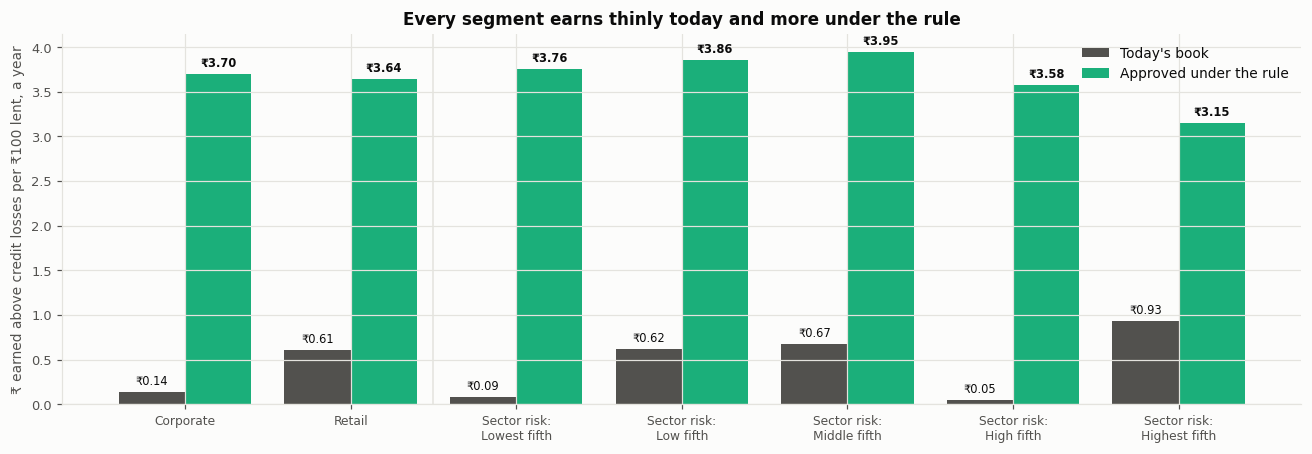

In [23]:
# Chart: what each ₹100 lent earns above credit losses, today vs under the rule, by segment.
fig, ax = plt.subplots(figsize=(12, 4.2))
x = np.arange(len(seg_res))
ax.bar(x - 0.2, seg_res["Earned per ₹100 today"], 0.4, color=INK_2, label="Today's book")
ax.bar(x + 0.2, seg_res["Earned per ₹100, approved"], 0.4, color=AQUA, label="Approved under the rule")
for i, (a, b) in enumerate(zip(seg_res["Earned per ₹100 today"], seg_res["Earned per ₹100, approved"])):
    ax.text(i - 0.2, a + 0.08, f"₹{a:.2f}", ha="center", fontsize=7.5)
    ax.text(i + 0.2, b + 0.08, f"₹{b:.2f}", ha="center", fontsize=7.5, fontweight="bold")
ax.axvline(1.5, color=GRID, lw=1)
ax.set_xticks(x, [f"{g}" if k == "Customer type" else f"Sector risk:\n{g}" for k, g in zip(seg_res.Kind, seg_res.Segment)],
              fontsize=8)
ax.set_ylabel("₹ earned above credit losses per ₹100 lent, a year"); ax.legend(frameon=False)
ax.set_title("Every segment earns thinly today and more under the rule")
fig.tight_layout(); save_chart(fig, "06_segments"); plt.show()

**Example loans.** One loan for each outcome, picked automatically as the loan closest to its group's median PD, to show the rule in ₹ for a single borrower.

In [24]:
examples = []
for label, mask in [("Approve", df.Decision == "Approve"),
                    ("Review: interest below expected loss", df.Reason.eq("Interest below expected loss")),
                    ("Review: weak collateral", df.Reason.eq("Weak collateral")),
                    ("Review: large loan", df.Reason.eq("Large loan (largest 5%)")),
                    ("Reject", df.Decision == "Reject")]:
    t = df[mask]
    if len(t):
        examples.append(t.iloc[(t.Predicted_PD - t.Predicted_PD.median()).abs().argsort()[:1]].assign(Example=label))
ex = pd.concat(examples)
ex_view = pd.DataFrame({
    "Example": ex.Example, "Loan_ID": ex.Loan_ID, "Loan (₹ lakh)": ex.Loan_Amount / LAKH,
    "Collateral (₹ lakh)": ex.Collateral_Value / LAKH, "Credit score": ex.Credit_Score,
    "Debt-to-income": ex.Debt_to_Income, "PD": ex.Predicted_PD, "Band": ex.Risk_Category.astype(str),
    "Interest a year (₹ lakh)": ex.Interest_Year / LAKH, "ECL (₹ lakh)": ex.ECL / LAKH,
    "Rate charged": ex.Rate, "Required rate": ex.Required_Rate, "Decision": ex.Decision.astype(str),
    "Reason": ex.Reason, "Actually defaulted": ex.Default_Flag.map({0: "No", 1: "Yes"})})
save_table(ex_view.round(4), "example_loans")
ex_view.style.format({"Loan (₹ lakh)": "₹{:.1f}", "Collateral (₹ lakh)": "₹{:.1f}", "Debt-to-income": "{:.2f}",
                      "PD": "{:.1%}", "Interest a year (₹ lakh)": "₹{:.2f}", "ECL (₹ lakh)": "₹{:.2f}",
                      "Rate charged": "{:.2%}", "Required rate": "{:.2%}"}, na_rep="—").hide(axis="index")

Example,Loan_ID,Loan (₹ lakh),Collateral (₹ lakh),Credit score,Debt-to-income,PD,Band,Interest a year (₹ lakh),ECL (₹ lakh),Rate charged,Required rate,Decision,Reason,Actually defaulted
Approve,202692,₹2.6,₹3.9,684,0.36,11.5%,Medium,₹0.26,₹0.12,9.99%,4.60%,Approve,Passes every test,No
Review: interest below expected loss,204526,₹15.2,₹27.6,671,0.53,25.6%,High,₹1.49,₹1.55,9.84%,10.23%,Review,Interest below expected loss,No
Review: weak collateral,201320,₹18.1,₹10.5,630,0.41,18.7%,High,₹1.88,₹1.35,10.40%,13.27%,Review,Weak collateral,No
Review: large loan,202067,₹35.0,₹68.9,759,0.34,18.6%,High,₹3.32,₹2.60,9.50%,7.44%,Review,Large loan (largest 5%),No
Reject,204380,₹21.0,₹26.1,681,0.71,39.1%,Very High,₹2.13,₹3.29,10.13%,—,Reject,PD over 30%,Yes


## 11. What the results say

### The answer to management's question (steps 3 and 5)

| Decision | Loans | ₹ lent | Actual default (95% range) | Expected loss rate | Interest − actual loss, per year |
| --- | --- | --- | --- | --- | --- |
| **Approve** | 2,934 (59%) | ₹285.9 crore (45%) | **11.3%** (10.3–12.5%) | 5.45% | **+₹10.45 crore** (₹8.62 to ₹12.11 crore) |
| **Review** | 1,045 (21%) | ₹163.9 crore (26%) | 21.8% (19.4–24.4%) | 8.79% | +₹0.59 crore |
| **Reject** | 1,021 (20%) | ₹189.8 crore (30%) | 42.7% (39.7–45.8%) | 17.41% | **−₹7.96 crore** |
| *Today's book* | *5,000* | *₹639.7 crore* | *19.9%* | *9.86%* | *+₹3.07 crore* |

- **Fewer defaults:** approved loans default 11.3%, against 19.9% for the book the bank actually made. The drop is far beyond chance (one-sided z test, p ≈ 10⁻²³).
- **More earned:** the approved loans earn ₹10.45 crore a year above their actual credit loss, more than three times what the whole of today's book earns (₹3.07 crore). This is before the cost of funds and running costs (see the cost sensitivity).
- **Losses avoided:** the rejected loans lose ₹7.96 crore a year on their own. They are a fifth of the loans but 52% of the expected loss.
- **Review is the "lend more" lever:** ₹163.9 crore of loans that are not bad but not yet acceptable. Each has a **required rate**: re-priced at that rate, or with more collateral, they can be lent safely.
- **The ECL is right in ₹:** total ECL is ₹63.04 crore against ₹62.72 crore actually lost at 40%, and every group's expected loss rate sits close to its actual loss rate.
- **The same pattern holds on the 1,000 test loans**, which were never used to choose anything: Approve 11.3%, Review 21.1%, Reject 40.1%, against 19.9% for the test book.

### How each step contributed (step 3)

| Step | Loans caught | Caught only by this step |
| --- | --- | --- |
| 1. PD over 30% → Reject | 1,021 | 1,021 |
| 2. Interest below expected loss → Review | 437 | 226 |
| 3a. Large loan (₹33.3 lakh or more) → Review | 125 | 76 |
| 3b. Weak collateral → Review | 736 | 497 |
| 4. Over the 6% risk-appetite cap → Review | 0 | 0 |

Counts cover every loan not rejected; a loan can be caught by several steps.

### The evidence behind the rule (step 4)

- **Borrower characteristics act through the PD.** Across 24 groups (fifths of debt-to-income, credit score, sector risk and employment length; past default; customer type), predicted PD and actual default move together. No gap is bigger than chance (all p > 0.05). A separate override would count the same risk twice.
- **Loan size.** The largest 5% of the loans that pass steps 1–2 (111 loans, ₹46.4 crore, 12% of their ₹) default 24.3%, against 12.5% for the rest. The model sees most of this (20.2% predicted; p = 0.29, so the gap could be chance). The flag rests on concentration: one default can lose up to ₹28.9 lakh.
  - **New finding:** for the very largest 2% (₹43 lakh or more, 39 loans), the gap is bigger than chance: 33.3% actual against 20.1% predicted (p = 0.046). The model under-predicts the biggest loans, and the 5% flag already sends them all to a person.
- **Collateral.** It does not predict default: 12.6% when the loan is above its collateral, 13.0% when within (p = 0.77). It changes loss size. At 50% recovery the book's average LGD is 37.4%, close to the brief's 40%. The 532 loans flagged for weak collateral (₹72.9 crore, typically 1.38× their collateral) default 19.7% and earn only +₹0.74 crore a year, against 11.7% and +₹10.67 crore for the rest.

### Risk appetite: the trade-off (step 6)

| Setting | Loans approved | ₹ approved | Expected loss rate | Actual default | Interest − actual loss |
| --- | --- | --- | --- | --- | --- |
| Today's book | 5,000 | ₹639.7 crore | 9.86% | 19.9% | +₹3.07 crore |
| **Rule, no cap = cap 6% (agreed)** | **2,934** | **₹285.9 crore** | **5.45%** | **11.3%** | **+₹10.45 crore** |
| Rule, cap 5% | 2,755 | ₹260.1 crore | 5.00% | 10.5% | +₹10.23 crore |
| Rule, cap 4% | 2,106 | ₹182.3 crore | 4.00% | 8.7% | +₹8.11 crore |
| Rule, cap 3% | 1,252 | ₹97.3 crore | 3.00% | 7.0% | +₹4.86 crore |

- **The agreed 6% cap does not bind:** the rule's approved book already sits at 5.45%, so the cap moves no loan. It is a guardrail that would act only if the PDs or the mix shifted.
- **A tighter cap is a Board choice of safety over income.** Going from 6% to 4% cuts defaults from 11.3% to 8.7%, but lends ₹103.6 crore less and earns ₹2.34 crore a year less. Every loan it removes still earns more than its expected loss.

### Cost of lending (step 7)

| Cost | Approve / Review / Reject | ₹ approved | Approved default | Median rate rise for underpriced Review loans | Approved: interest − actual loss − cost | Today's book, same measure |
| --- | --- | --- | --- | --- | --- | --- |
| 0% (base) | 2,934 / 1,045 / 1,021 | ₹285.9 crore | 11.3% | +1.64 points | +₹10.45 crore | +₹3.07 crore |
| 1% | 2,521 / 1,458 / 1,021 | ₹236.1 crore | 10.6% | +2.10 | +₹6.85 crore | −₹3.32 crore |
| 2% | 2,006 / 1,973 / 1,021 | ₹179.0 crore | 9.1% | +2.38 | +₹4.40 crore | −₹9.72 crore |
| 3% | 1,432 / 2,547 / 1,021 | ₹120.5 crore | 8.8% | +2.70 | +₹2.16 crore | −₹16.11 crore |

- **Today's book breaks even at a cost of only 0.48% a year.** At any realistic cost it loses money.
- **The rule's approved book stays profitable at every cost tested.**
- Cost only moves loans between Approve and Review. Reject never changes, because it depends on PD alone.

### LGD (step 8)

| LGD | Approve / Review / Reject | Decisions changed | Approved default | Approved: interest − actual loss at this LGD |
| --- | --- | --- | --- | --- |
| Flat 30% | 3,154 / 825 / 1,021 | 220 | 12.6% | +₹14.27 crore |
| **Flat 40% (base)** | **2,934 / 1,045 / 1,021** | — | **11.3%** | **+₹10.45 crore** |
| Flat 50% | 2,444 / 1,535 / 1,021 | 490 | 9.9% | +₹6.74 crore |
| Flat 60% | 1,954 / 2,025 / 1,021 | 980 | 8.7% | +₹4.81 crore |
| Collateral-aware, 50% recovery | 3,160 / 819 / 1,021 | 226 | 12.5% | +₹14.91 crore |
| Collateral-aware, 60% recovery | 3,407 / 572 / 1,021 | 473 | 13.4% | +₹19.87 crore |
| Collateral-aware, 70% recovery | 3,532 / 447 / 1,021 | 598 | 13.4% | +₹24.01 crore |

- **Reject never changes, and the approved book stays profitable under every LGD tested.**
- A higher LGD makes the rule stricter: more loans move to Review.
- Counting collateral (at any recovery from 50% to 70%) approves more loans, because well-covered loans lose little on default.
- 1,665 loans (₹212.7 crore) are bigger than their collateral. They are the ones a recovery assumption matters for most.

### Scorecard against the bank's own view (step 9)

| PD used in the same rule | Approve / Review / Reject | ₹ approved | Approved default | Interest − actual loss | Per ₹100 approved |
| --- | --- | --- | --- | --- | --- |
| **Scorecard (used)** | 2,934 / 1,045 / 1,021 | ₹285.9 crore | **11.3%** | **+₹10.45 crore** | **₹3.66** |
| Champion (bank's price) | 3,210 / 958 / 832 | ₹322.4 crore | 14.0% | +₹7.36 crore | ₹2.28 |

- **With the scorecard, the rule earns ₹3.09 crore a year more, while lending ₹36.5 crore less.** It earns ₹3.66 per ₹100 approved against ₹2.28.
- **The turning point is not a concern here.** The rule approves 58.7% of loans, well below Task 1's 73%. At this level the scorecard's ranking alone loses ₹1.93 crore less than the champion's (₹0.40 crore less on the test loans).
  - Steps 1–2 alone would approve 70.8%, close to the turning point, where ranking alone is a tie (+₹0.23 crore; −₹0.21 crore on test loans).
  - The size and collateral flags moved the rule into the range where the scorecard is clearly better.
- **Board warning:** if the bank widens approval above about 73%, the scorecard's ranking advantage reverses. Its value there would come from pricing, not from choosing who gets a loan.

### Concentration (step 10)

- The approved book keeps today's mix: Corporate is 27.1% of today's ₹ and 26.4% of approved ₹. Retail and Corporate are approved at the same rate (58.7% vs 58.6%) and default alike (11.3% vs 11.4%).
- Each fifth of sector risk holds 19–21% of approved ₹. Approved default is a little higher in the two riskiest fifths (13.2%, 12.8%) than in the safest (10.1%), but no fifth dominates.
- No concentration limit is set, because the data gives no basis for one. This is for the Board to watch.

### Results by segment (step 10, decision M2-22)

| Segment | ₹ lent today | Default today → approved | Earned per ₹100 lent today | Earned per ₹100, approved | Expected return, approved |
| --- | --- | --- | --- | --- | --- |
| Retail | ₹466.4 crore | 19.9% → 11.3% | ₹0.61 | ₹3.64 | 3.30% |
| Corporate | ₹173.2 crore | 20.0% → 11.4% | ₹0.14 | ₹3.70 | 3.31% |
| Sector risk, lowest fifth | ₹122.1 crore | 18.2% → 10.1% | ₹0.09 | ₹3.76 | 3.35% |
| Sector risk, low fifth | ₹130.5 crore | 19.5% → 10.7% | ₹0.62 | ₹3.86 | 3.19% |
| Sector risk, middle fifth | ₹127.5 crore | 20.0% → 9.9% | ₹0.67 | ₹3.95 | 3.25% |
| Sector risk, high fifth | ₹127.3 crore | 21.3% → 13.2% | ₹0.05 | ₹3.58 | 3.31% |
| Sector risk, highest fifth | ₹132.3 crore | 20.7% → 12.8% | ₹0.93 | ₹3.15 | 3.40% |

"Earned" = interest − actual loss at 40%, before the cost of funds. "Expected return" = interest rate − ECL rate.

- **Every segment earns thinly today, and every segment earns ₹3.15–₹3.95 per ₹100 under the rule.** The rule works the same way across the book.
- **Corporate earns less than Retail today (₹0.14 vs ₹0.61 per ₹100), but the gap is within chance:** the bootstrap 95% range of the difference is −₹0.90 to +₹1.91. It is not evidence that Corporate lending is worse; both segments are thin, and Corporate's own range includes losing money.
- **Under the rule the two segments are indistinguishable:** approved default 11.3% vs 11.4% (p = 0.98).
- **Sector risk:** the two riskiest fifths keep a slightly higher approved default (13.2%, 12.8% against 9.9–10.7%), and the riskiest earns the least under the rule (₹3.15). A weak pattern, matching Task 1 (default rises only from 18.2% to 20.7% across fifths): worth watching, not acting on.

### Limits of this analysis

- **LGD and recovery are assumed, not measured:** the data has no recovery amounts. The sensitivity shows the rule holds across 30–60% flat and 50–70% recovery.
- **One-year view:** both PD and interest are yearly. Default does not rise with loan term in this data (Task 1), which supports it.
- **The 5% size cut-off and the 50% recovery are judgements.** That is why they only send loans to a person, never decide on their own.
- **Default outcomes are only seen for loans the bank made.** How rejected applicants would have behaved is unknown, a standard limit of credit data ("reject inference").
- **No cost-of-funds figure in the data:** the base uses none, and 1–3% is shown as a sensitivity.

## 11b. What goes to Module 9: lending return and risk per ₹ (decision M2-23)
Module 9 compares every business on the **same fields**: return per ₹ deployed, a bad-year result, capacity, evidence, how fast money comes back, gaps and controls. Here they are for lending, by Retail and Corporate, for the **approved** loans and for the **Review queue**.

| Measure | How it is worked out |
| --- | --- |
| Return per ₹ lent | (interest a year − ECL) ÷ ₹ lent: what lending earns above expected credit losses, before cost of funds and running costs |
| What it really earned | (interest − actual losses of the loans that defaulted) ÷ ₹ lent: a check against what happened |
| Bad year | Every PD doubled (a recession), LGD 40%: the credit stress named in the project plan |
| Severe year | PD doubled and LGD 60% (collateral fetches less in a downturn) |
| 1-in-100 year from luck alone | 3,000 random draws of which loans default, each at its own PD (seed 42); defaults independent, so this **understates** a real recession |

In [25]:
def lending_fields(t: pd.DataFrame) -> dict:
    """Return per ₹ lent and its bad-year results for one group of loans (all % of ₹ lent, a year)."""
    L, P, lent = t.Loan_Amount, t.Predicted_PD, t.Loan_Amount.sum()
    income = t.Interest_Year.sum()
    result = lambda pd_mult, lgd: 100 * (income - (np.minimum(P * pd_mult, 1) * lgd * L).sum()) / lent
    draws = [((m9_rng.random(len(t)) < P.to_numpy()) * LGD * L.to_numpy()).sum() for _ in range(3000)]
    return {"Loans": len(t), "₹ lent (crore)": lent / CRORE, "Interest rate (%)": 100 * income / lent,
            "Expected loss (%)": 100 * t.ECL.sum() / lent, "Return per ₹ lent (% a year)": result(1, LGD),
            "What it really earned (% a year)": 100 * (income - t.Actual_Loss.sum()) / lent,
            "Bad year: PD × 2 (% a year)": result(2, LGD), "Severe year: PD × 2, LGD 60% (% a year)": result(2, 0.60),
            "1-in-100 year, luck alone (% a year)": 100 * (income - np.percentile(draws, 99)) / lent}


m9_rng = np.random.default_rng(SEED)
lend_rows = []
for dec in ["Approve", "Review"]:
    for typ in ["Retail", "Corporate", "All"]:
        t = df[(df.Decision == dec) & ((df.Customer_Type == typ) if typ != "All" else True)]
        lend_rows.append({"Group": dec, "Loan type": typ, **lending_fields(t)})
lending_m9 = pd.DataFrame(lend_rows)
display(lending_m9.round(2))
ap = lending_m9.set_index(["Group", "Loan type"]).loc[("Approve", "All")]
print(f"Approved loans earn {ap['Return per ₹ lent (% a year)']:.1f}% a year above expected losses, but a recession year (PD × 2) turns that into "
      f"{ap['Bad year: PD × 2 (% a year)']:.1f}% ({ap['Severe year: PD × 2, LGD 60% (% a year)']:.1f}% if collateral fetches less). "
      "The Review queue earns about 1% even in a normal year. All figures are before the cost of funds (not in the data).")

M9_CAT = {"Retail": "Retail lending", "Corporate": "Corporate lending"}
m9_inputs = pd.DataFrame([{
    "Category": M9_CAT[typ], "What NovaFin would put money into": f"The {int(r.Loans):,} {typ} loans the rule approves",
    "Return per ₹ deployed (% a year)": round(r["Return per ₹ lent (% a year)"], 2),
    "Return range (% a year)": f"{r['Severe year: PD × 2, LGD 60% (% a year)']:.1f} (severe year) to {r['What it really earned (% a year)']:.1f} (what these loans really earned)",
    "Bad-year result per ₹ (% a year)": round(r["Bad year: PD × 2 (% a year)"], 2),
    "How the bad year is defined": "Every PD doubled (a recession), LGD 40%; severe: also LGD 60%",
    "Capacity (₹ crore)": round(r["₹ lent (crore)"], 2), "Evidence strength": "Strong: PD scorecard validated on unseen loans (Task 1–2)",
    "How fast the money can come back": "About 4 years (average term 48 months); repaid in instalments",
    "Data gap or assumption": "No cost of funds, running costs or recovery data (LGD 40% assumed); Review queue (₹163.9 crore) earns about 1% and only once re-priced",
    "Controls": "Approve / Review / Reject rule; PD cap; re-price by scorecard band; monitor PD drift",
    "Detail tab": "T3 loan decisions", "Detail column(s)": "Customer_Type, Decision, Loan_Amount (₹), ECL a year (₹), Interest a year (₹)",
    "Decision": "M2-23"} for (grp, typ), r in lending_m9.set_index(["Group", "Loan type"]).iterrows() if grp == "Approve" and typ != "All"])
display(m9_inputs[["Category", "Return per ₹ deployed (% a year)", "Bad-year result per ₹ (% a year)", "Capacity (₹ crore)"]])

,Group,Loan type,Loans,₹ lent (crore),Interest rate (%),Expected loss (%),Return per ₹ lent (% a year),What it really earned (% a year),Bad year: PD × 2 (% a year),"Severe year: PD × 2, LGD 60% (% a year)","1-in-100 year, luck alone (% a year)"
0,Approve,Retail,2169,210.52,8.73,5.44,3.30,3.64,-2.14,-7.58,2.45
1,Approve,Corporate,765,75.42,8.81,5.50,3.31,3.70,-2.19,-7.68,1.80
2,Approve,All,2934,285.94,8.75,5.45,3.30,3.66,-2.15,-7.61,2.60
3,Review,Retail,773,120.32,9.80,8.84,0.96,0.08,-7.88,-16.73,-0.81
4,Review,Corporate,272,43.61,9.63,8.66,0.97,1.12,-7.68,-16.34,-2.05
5,Review,All,1045,163.93,9.76,8.79,0.96,0.36,-7.83,-16.62,-0.51


Approved loans earn 3.3% a year above expected losses, but a recession year (PD × 2) turns that into -2.2% (-7.6% if collateral fetches less). The Review queue earns about 1% even in a normal year. All figures are before the cost of funds (not in the data).


,Category,Return per ₹ deployed (% a year),Bad-year result per ₹ (% a year),Capacity (₹ crore)
0,Retail lending,3.30,-2.14,210.52
1,Corporate lending,3.31,-2.19,75.42


## 12. Save the outputs

**`FINAL_M2_T3_loan_decisions.csv`: the decision file, one row per loan, no blank cells, no codes.** It serves three readers:
- **Later modules and analysis (numbers, complete):** Loan_ID, Customer_Type, loan and collateral in ₹, PD and band, ECL, interest a year, rate charged, expected loss rate, expected return (rate − expected loss rate) and required rate, for every loan. Module 9 needs approved volume, ECL rate and expected return for Retail and Corporate separately, and can add these columns up.
- **The credit team (words):** every check with its numbers, the decision path, and **an action for each Review loan**: the rate to offer, the collateral that would pass at today's rate, or a person's check for a large loan.
- **An evaluator or regulator (words):** the full reason, with the deciding factor first and every other check after it.

Also saved: `module9_inputs.csv` and `module9_lending_risk.csv` (step 11b: lending return and bad-year results per ₹ for Module 9), the tables and charts above, and `key_numbers.json` with the headline numbers of this run, including the Retail / Corporate figures for Module 9.

In [26]:
lgd_c = collateral_lgd(df)                                    # collateral-aware LGD at 50% recovery
el_c = df.Predicted_PD * lgd_c                                # expected loss rate once collateral is counted
req_all = COST + df.Predicted_PD * np.maximum(LGD, lgd_c)     # required rate, defined for every loan
# Collateral that would pass step 3b at today's rate:  Rate > PD × (1 − 50% × C ÷ L)  ⇔  C > L × (1 − Rate ÷ PD) ÷ 50%
coll_needed = (df.Loan_Amount * (1 - df.Rate / df.Predicted_PD) / RECOVERY).clip(lower=0)
approved_rate = df.loc[df.Decision == "Approve", "ECL"].sum() / df.loc[df.Decision == "Approve", "Loan_Amount"].sum()


def lakh(v):
    """₹ amount in words-friendly lakh, e.g. ₹18.1 lakh."""
    return f"₹{v / LAKH:,.1f} lakh"


def checks(r) -> pd.Series:
    """Every check for one loan, in words with its numbers, plus the action and the full reason."""
    i = r.name
    pd_ok = r.Predicted_PD <= PD_REJECT
    c1 = (f"Pass: PD {r.Predicted_PD:.1%} is at or below 30% ({r.Risk_Category})" if pd_ok
          else f"Fail: PD {r.Predicted_PD:.1%} is above 30% ({r.Risk_Category})")
    status = ("Not deciding (rejected at step 1)" if not pd_ok else "Fail" if r.Flag_Underpriced else "Pass")
    c2 = f"{status}: charges {r.Rate:.2%}, expected loss {r.EL_Rate:.2%} a year"
    c3a = (f"Flag: {lakh(r.Loan_Amount)}, in the largest 5% (₹{SIZE_CUTOFF / LAKH:.1f} lakh or more); "
           f"one default could lose {lakh(r.Loan_Amount * LGD)}" if r.Loan_Amount >= SIZE_CUTOFF
           else f"Pass: {lakh(r.Loan_Amount)}, below ₹{SIZE_CUTOFF / LAKH:.1f} lakh")
    ratio = r.Loan_Amount / r.Collateral_Value
    c3b = (f"{'Flag' if r.Rate <= el_c[i] else 'Pass'}: loan is {ratio:.2f}× collateral; with collateral counted, "
           f"expected loss {el_c[i]:.2%} a year vs {r.Rate:.2%} charged")
    if r.Decision == "Approve":
        c4 = f"Within the 6% cap: approved book at {approved_rate:.2%}"
    elif "cap" in r.Reason:
        c4 = "Moved to Review: approved book over the 6% cap"
    else:
        c4 = "Not applicable: not approved"

    if r.Decision == "Approve":
        path, action = "Approve: passes every check", "None: lend at the rate charged"
    elif r.Decision == "Reject":
        path = "Reject: PD above 30%"
        action = (f"Decline: no rate within risk appetite covers a {r.Predicted_PD:.0%} chance of default "
                  f"(break-even rate {req_all[i]:.2%})")
    else:
        path = "Review: " + r.Reason.lower()
        steps = []
        if r.Flag_Underpriced:
            steps.append(f"offer at least {req_all[i]:.2%} (now {r.Rate:.2%}, +{(req_all[i] - r.Rate) * 100:.2f} points)")
        elif r.Flag_Weak_Collateral:
            steps.append(f"offer at least {req_all[i]:.2%} (now {r.Rate:.2%}) or raise collateral to "
                         f"{lakh(coll_needed[i])} (+{lakh(coll_needed[i] - r.Collateral_Value)})")
        if r.Flag_Large:
            steps.append(f"credit committee check of the {lakh(r.Loan_Amount)} exposure")
        if "cap" in r.Reason:
            steps.append("hold until the approved book is back within the 6% cap")
        action = "; ".join(steps)
        action = action[0].upper() + action[1:]
    deciding = {"Approve": "passes every check", "Reject": c1.replace("Fail: ", ""), "Review": r.Reason}[r.Decision]
    others = [c for c in [c1, c2, c3a, c3b] if not (r.Decision == "Reject" and c == c1)]
    full = f"{r.Decision}: {deciding}. Other checks: " + "; ".join(others) + "."
    return pd.Series({"Check: PD": c1, "Check: interest covers expected loss": c2, "Check: loan size": c3a,
                      "Check: collateral": c3b, "Check: risk appetite": c4, "Decision path": path,
                      "Action": action, "Full reason": full})


words = df.apply(checks, axis=1)
decisions = pd.concat([
    pd.DataFrame({"Loan_ID": df.Loan_ID, "Customer_Type": df.Customer_Type,
                  "Loan_Amount (₹)": df.Loan_Amount.round(2), "Collateral_Value (₹)": df.Collateral_Value.round(2),
                  "Predicted_PD": df.Predicted_PD.round(6), "Risk_Category": df.Risk_Category.astype(str),
                  "ECL a year (₹)": df.ECL.round(2), "Interest a year (₹)": df.Interest_Year.round(2),
                  "Rate charged (%)": (df.Rate * 100).round(2), "Expected loss rate (%)": (df.EL_Rate * 100).round(3),
                  "Expected return (%)": ((df.Rate - df.EL_Rate) * 100).round(3),
                  "Required rate (%)": (req_all * 100).round(3), "Decision": df.Decision.astype(str)}),
    words], axis=1).sort_values("Loan_ID").reset_index(drop=True)
assert len(decisions) == 5000 and decisions.notna().all().all()       # no blank cells
save_table(decisions, "FINAL_M2_T3_loan_decisions")
pd.set_option("display.max_colwidth", 120)
display(decisions.groupby("Decision", observed=True).head(1).T)        # one example of each decision, every column

# Figures Module 9 needs: approved volume, ECL rate and expected return, for Retail and Corporate separately.
module9 = {}
for seg in ["Retail", "Corporate", "All"]:
    s = df if seg == "All" else df[df.Customer_Type == seg]
    for scope, t in [("book", s), ("approved", s[s.Decision == "Approve"])]:
        lent = t.Loan_Amount.sum()
        module9[f"{seg}_{scope}"] = {"crore": round(lent / CRORE, 2),
                                     "rate": round(float(t.Interest_Year.sum() / lent), 4),
                                     "ecl_rate": round(float(t.ECL.sum() / lent), 4),
                                     "expected_return": round(float((t.Interest_Year.sum() - t.ECL.sum()) / lent), 4)}
print(pd.DataFrame(module9).T.to_string())


def r4(v):
    return round(float(v), 4)


key = {
    "loans": len(df), "size_cutoff_lakh": round(SIZE_CUTOFF / LAKH, 2),
    "total_ecl_crore": round(df.ECL.sum() / CRORE, 2), "actual_loss_crore": round(df.Actual_Loss.sum() / CRORE, 2),
    "decisions": {d: int((df.Decision == d).sum()) for d in DECISIONS},
    "decision_crore": {d: round(outcome.loc[d, "₹ lent (crore)"], 2) for d in DECISIONS},
    "decision_default_rate": {d: r4(outcome.loc[d, "Actual default rate"]) for d in DECISIONS + ["Today's book"]},
    "approve_expected_loss_rate": r4(outcome.loc["Approve", "Expected loss rate"]),
    "earn_above_actual_loss_crore": {g: round(outcome.loc[g, "Interest − actual loss (crore)"], 2) for g in DECISIONS + ["Today's book"]},
    "approve_earn_range_crore": [round(float(x), 2) for x in EARN_RANGE],
    "approve_vs_book_p": float(p_drop), "test_consistent": TEST_CONSISTENT, "cap_binds": CAP_BINDS,
    "book_breakeven_cost": r4(BOOK_BREAKEVEN_COST), "approval_share": r4(APPROVAL_SHARE),
    "turning_point": TURNING_POINT, "module9": module9,
    "segments": {r.Segment: {"earn_today_crore": round(float(r["Interest − actual loss today (crore)"]), 2),
                             "earn_approved_crore": round(float(r["Interest − actual loss, approved (crore)"]), 2),
                             "default_approved": r4(r["Default, approved"])} for _, r in seg_res.iterrows()},
    "segment_approved_p": round(float(p_seg_appr), 3),
    "segment_earn_gap_range": [round(float(x), 2) for x in SEG_GAP["Retail − Corporate"]], "corporate_gap_real": CORP_GAP_REAL,
}
key["module9_lending"] = {f"{r.Group} {r['Loan type']}": {"return_pct": r4(r["Return per ₹ lent (% a year)"]), "bad_year_pct": r4(r["Bad year: PD × 2 (% a year)"]),
                          "severe_pct": r4(r["Severe year: PD × 2, LGD 60% (% a year)"]), "crore": round(float(r["₹ lent (crore)"]), 2)} for _, r in lending_m9.iterrows()}
save_table(lending_m9.round(4), "module9_lending_risk")
save_table(m9_inputs, "module9_inputs")                                      # the standard Module 9 fields (step 11b)
(OUT_DIR / "key_numbers.json").write_text(json.dumps(key, indent=1), encoding="utf-8")
print(decisions.head())
print("Saved to", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())
print(sorted(p.name for p in OUT_DIR.iterdir()))

,0,3,7
Loan_ID,200001,200004,200008
Customer_Type,Corporate,Corporate,Corporate
Loan_Amount (₹),1968503.82,3855380.75,2015226.77
Collateral_Value (₹),2690085.58,5571538.48,2343021.65
Predicted_PD,0.18858,0.476837,0.281094
Risk_Category,High,Very High,High
ECL a year (₹),148488.18,735355.28,226587.26
Interest a year (₹),176377.94,500042.88,176332.34
Rate charged (%),8.96,12.97,8.75
Expected loss rate (%),7.543,19.073,11.244


                     crore    rate  ecl_rate  expected_return
Retail_book         466.43  0.1025    0.0975           0.0050
Retail_approved     210.52  0.0873    0.0544           0.0330
Corporate_book      173.22  0.1037    0.1013           0.0024
Corporate_approved   75.42  0.0881    0.0550           0.0331
All_book            639.65  0.1029    0.0986           0.0043
All_approved        285.94  0.0875    0.0545           0.0330
   Loan_ID Customer_Type  Loan_Amount (₹)  Collateral_Value (₹)  Predicted_PD Risk_Category  ECL a year (₹)  Interest a year (₹)  Rate charged (%)  Expected loss rate (%)  Expected return (%)  Required rate (%)  \
0   200001     Corporate       1968503.82            2690085.58      0.188580          High       148488.18            176377.94              8.96                   7.543                1.417              7.543   
1   200002        Retail       1932554.81            2542892.81      0.076655        Medium        59256.00            151125.79          